<a href="https://colab.research.google.com/github/tommbk50-hub/Cheminformatics/blob/main/Copy_of_AiZynthFinder_with_Gemini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AiZynthFinder + Gemini: Interactive Retrosynthesis & Medicinal Chemistry Assistant

This notebook combines **AiZynthFinder** (an AI-driven retrosynthesis engine using USPTO reaction templates and ZINC commercial stock) with **RDKit** cheminformatics heuristics and **Google Gemini** to plan, score, and analyze synthetic routes for target molecules.

### How It Works
1. **Setup & Engine Initialization (Cells 1–3):** Installs dependencies, downloads pretrained USPTO neural network models and ZINC stock data, defines medicinal chemistry SMARTS rules and Gemini classification helpers, and initializes the AiZynthFinder engine.
2. **Target Selection & Constraints (Cell 4):** Lets you input a target molecule by name, ID (PubChem, DrugBank, ChEMBL, InChIKey, CAS), SMILES, or by drawing it in an interactive JSME sketcher. You can also lock specific substructures/atoms and upload an in-house lab inventory of building blocks.
3. **Search Configuration & Execution (Cells 5A–5B):** Configures the tree search algorithm (`Retro*` or `MCTS`), ranking profile (`balanced`, `medchem_fast`, `process_scaleup`, `green_safe`), scale, and reaction exclusions. Running the search generates routes, classifies each step with Gemini + RDKit (conditions, safety/green scores, selectivity warnings, protecting groups, stereochemistry), and renders interactive 2D SVG route cards.
4. **Interactive AI Analysis (Cell 6):** Feeds the top retrosynthesis routes into a Gemini chat interface equipped with Python tools to re-run searches with new constraints, generate ELN stoichiometry protocols, and evaluate routes.

### Cell 1: Install Dependencies & Download Models
Installs all required Python packages (`rdkit`, `aizynthfinder`, `onnxruntime`, `google-genai`, `pydantic`, etc.) and downloads the public USPTO expansion, ringbreaker, and filter ONNX models along with the ZINC stock database into `./data` (skipping the download if `data/config.yml` already exists).

In [ ]:
# @title 1. Install Dependencies & Download Models
import os

# Install all Python dependencies in a single pip invocation
!pip install -q rdkit onnxruntime tables scipy pydantic deprecated jinja2 networkx pillow requests tqdm pyyaml rdchiral paretoset marshmallow jedi Reaction-Utils google-genai markdown
!pip install -q --ignore-requires-python --no-deps aizynthfinder

# Download USPTO models and ZINC stock only if not already present
if not os.path.exists("data/config.yml"):
    !mkdir -p data && download_public_data data
else:
    print("✅ Models and ZINC stock already present in ./data")

✅ Models and ZINC stock already present in ./data


In [ ]:
# @title
!pip show aizynthfinder

Name: aizynthfinder
Version: 4.4.1
Summary: Retrosynthetic route finding using neural network guided Monte-Carlo tree search
Home-page: https://github.com/MolecularAI/aizynthfinder/
Author: Molecular AI group
Author-email: samuel.genheden@astrazeneca.com
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: dask, deprecated, ipywidgets, jinja2, jupyter, jupytext, matplotlib, networkx, notebook, numpy, onnxruntime, pandas, paretoset, pillow, rdchiral, rdkit, reaction-utils, requests, seaborn, tables, tqdm
Required-by: 


### Cell 2: Core Definitions — SMARTS Library, Reaction Classifiers & Gemini Helpers
Defines the core chemistry and AI helper functions used throughout the notebook:
- **Gemini Client:** Initializes a cached `genai.Client` using the `KDD_GEMINI_API_KEY` secret or environment variable.
- **SMARTS & Local Heuristics:** Compiles a dictionary of medicinal chemistry functional groups (`MEDCHEM_SMARTS`) and rule-based reaction classifiers (`RDKIT_REACTION_RULES`) to evaluate chemoselectivity risks, protecting group needs, green chemistry/safety scores (1–5), solvent swaps, and stereochemical changes.
- **Batched Gemini Classification:** Uses `batch_classify_with_gemini()` (with structured Pydantic output) to label unique reaction steps and cache results, falling back to local RDKit heuristics if the API is unavailable.
- **RDKit Utilities:** Includes helpers for 2D SVG molecule/reaction rendering, competing byproduct enumeration, LC-MS monoisotopic ion prediction, and aqueous workup/chromatography recommendations.

In [ ]:
# @title 2. Core Definitions: SMARTS Library, Reaction Classifiers & Gemini Helpers
import os
import json
import logging
from pydantic import BaseModel
from rdkit import Chem
from google import genai
from google.genai import types

# --- 1. API Key & Client Singleton ---
def get_gemini_client():
    """Returns a cached genai.Client instance if KDD_GEMINI_API_KEY is available."""
    if "_GEMINI_CLIENT" in globals() and globals()["_GEMINI_CLIENT"] is not None:
        return globals()["_GEMINI_CLIENT"]

    api_key = None
    try:
        from google.colab import userdata
        api_key = userdata.get("KDD_GEMINI_API_KEY")
    except Exception:
        api_key = os.environ.get("KDD_GEMINI_API_KEY")

    if api_key:
        globals()["_GEMINI_CLIENT"] = genai.Client(api_key=api_key)
        return globals()["_GEMINI_CLIENT"]
    return None

# --- 2. Medicinal Chemistry SMARTS Dictionary ---
# Pipe '|' separates sub-patterns so RDKit compiles each valid SMARTS string into a list
RAW_SMARTS = {
    "boronic": "[#5](O)O|[#5]1O[#6][#6]O1",
    "stannane": "[#50]",
    "zinc_magnesium": "[#12,#30]",
    "silicon_coupling": "[#14](F)|[#14](O)",
    "terminal_alkyne": "[CX2]#[CX2H1]",
    "internal_alkyne": "[CX2]#[CX2;!H1]",
    "alkene": "[CX3]=[CX3]",
    "aryl_halide_pseudohalide": "c[Cl,Br,I]|cOS(=O)(=O)C(F)(F)F",
    "alkyl_lg": "[CX4][Cl,Br,I]|[#6]OS(=O)(=O)[#6]",
    "carboxylic_acid": "[CX3](=O)[OX2H1]",
    "ester": "[#6][CX3](=O)[OX2][#6]",
    "benzyl_ester": "[#6][CX3](=O)[OX2]Cc1ccccc1",
    "acyl_halide": "[CX3](=O)[Cl,Br,F]",
    "anhydride": "[CX3](=O)O[CX3](=O)",
    "amide": "[#6][CX3](=O)[NX3]",
    "primary_amide": "[CX3](=O)[NX3H2]",
    "thioamide": "[#6](=[#16])[#7]",
    "amine_1_2": "[NX3;H2,H1;!$(NC=O);!$(NS=O)]",
    "tert_amine": "[NX3;H0;!$(NC=O);!$(NS=O)]",
    "aryl_amine": "c[NX3]",
    "nitro": "[$([NX3](=O)=O),$([NX3+](=O)[O-])]",
    "nitrile": "[CX2]#[NX1]",
    "azide": "[NX2]=[NX2+]=[NX1-]|[NX1-]=[NX2+]=[NX2]",
    "triazole": "c1ncnn1|c1nnn[nH]1",
    "tetrazole": "c1nnnn1",
    "thiazole": "c1ncsc1",
    "imidazole_oxazole": "c1nc[nH,o]c1",
    "indole": "c1ccc2[nH]ccc2c1",
    "aldehyde_ketone": "[CX3H1](=O)[#6]|[CX3](=O)([#6])[#6]",
    "alcohol": "[CX4][OX2H1]",
    "phenol": "c[OX2H1]",
    "ether": "[#6][OX2][#6]",
    "aryl_ether": "c[OX2][CX4]",
    "epoxide": "C1OC1",
    "sulfonamide": "S(=O)(=O)[NX3]",
    "sulfonyl_chloride": "S(=O)(=O)[Cl]",
    "thiol": "[#6][SX2H1]",
    "thioether": "[#6][SX2][#6]",
    "sulfone_sulfoxide": "[#16X4](=O)(=O)|[#16X3](=O)",
    "boc": "[NX3]C(=O)OC(C)(C)C",
    "cbz": "[NX3]C(=O)OCc1ccccc1",
    "silyl_ether": "[#8][#14]([#6])([#6])[#6]",
    "phosphorus_ylide_phosphonate": "[#15]",
}

MEDCHEM_SMARTS = {
    k: [Chem.MolFromSmarts(p) for p in v.split("|") if Chem.MolFromSmarts(p) is not None]
    for k, v in RAW_SMARTS.items()
}

def has_fg(mols, key):
    """Checks if any molecule in `mols` matches any SMARTS pattern for `key`."""
    pats = MEDCHEM_SMARTS.get(key, [])
    return any(m is not None and m.HasSubstructMatch(pat) for m in mols for pat in pats)

# --- 3. Local RDKit Heuristic Classifier (with Conditions) ---
# Ordered list of (Condition_Lambda(R, P), Reaction_Name, Typical_Conditions)
RDKIT_REACTION_RULES = [
    # 1. Cross-Couplings
    (lambda R, P: has_fg(R, "boronic") and (has_fg(R, "aryl_halide_pseudohalide") or has_fg(R, "alkyl_lg")),
     "Suzuki-Miyaura Cross-Coupling", "Pd(dppf)Cl2 or Pd(PPh3)4, K2CO3, Dioxane/H2O, 80-100 °C"),
    (lambda R, P: has_fg(R, "boronic") and (has_fg(R, "amine_1_2") or has_fg(R, "phenol")),
     "Chan-Lam Coupling", "Cu(OAc)2, Pyridine or Et3N, DCM, O2 (air), RT"),
    (lambda R, P: has_fg(R, "stannane") and has_fg(R, "aryl_halide_pseudohalide"),
     "Stille Cross-Coupling", "Pd(PPh3)4, LiCl, DMF or Dioxane, 90 °C"),
    (lambda R, P: has_fg(R, "terminal_alkyne") and has_fg(R, "aryl_halide_pseudohalide") and has_fg(P, "internal_alkyne"),
     "Sonogashira Cross-Coupling", "Pd(PPh3)2Cl2, CuI, Et3N, THF/DMF, RT-60 °C"),
    (lambda R, P: has_fg(R, "aryl_halide_pseudohalide") and has_fg(R, "amine_1_2") and has_fg(P, "aryl_amine"),
     "Buchwald-Hartwig Amination / SNAr", "Pd2(dba)3, XPhos/BINAP, NaOtBu, Toluene, 100 °C"),
    (lambda R, P: has_fg(P, "boronic") and has_fg(R, "aryl_halide_pseudohalide") and not has_fg(R, "boronic"),
     "Miyaura Borylation", "B2pin2, Pd(dppf)Cl2, KOAc, Dioxane, 90 °C"),
    (lambda R, P: has_fg(R, "aryl_halide_pseudohalide") and not has_fg(P, "aryl_halide_pseudohalide") and has_fg(R, "alkene") and has_fg(P, "alkene"),
     "Mizoroki-Heck Reaction", "Pd(OAc)2, P(o-tol)3, Et3N, DMF/MeCN, 100 °C"),
    (lambda R, P: has_fg(R, "zinc_magnesium") and has_fg(R, "aryl_halide_pseudohalide"),
     "Kumada / Negishi Cross-Coupling", "Pd(PPh3)4 or Ni(dppe)Cl2, THF, RT-65 °C"),

    # 2. Deprotections
    (lambda R, P: has_fg(R, "boc") and not has_fg(P, "boc"),
     "N-Boc Deprotection (Acidolysis)", "TFA / DCM or 4M HCl in Dioxane, RT"),
    (lambda R, P: has_fg(R, "cbz") and not has_fg(P, "cbz"),
     "N-Cbz Deprotection (Hydrogenolysis)", "H2, Pd/C, MeOH or EtOAc, RT"),
    (lambda R, P: has_fg(R, "silyl_ether") and not has_fg(P, "silyl_ether"),
     "Silyl Ether Deprotection (Desilylation)", "TBAF, THF, 0 °C to RT"),
    (lambda R, P: has_fg(P, "carboxylic_acid") and has_fg(R, "benzyl_ester") and not has_fg(R, "carboxylic_acid"),
     "Benzyl Ester Cleavage (Hydrogenolysis / Hydrolysis)", "H2, Pd/C in MeOH/THF (or LiOH, THF/H2O)"),
    (lambda R, P: has_fg(P, "carboxylic_acid") and has_fg(R, "ester") and not has_fg(R, "carboxylic_acid"),
     "Ester Hydrolysis / Saponification", "LiOH or NaOH, THF / MeOH / H2O, RT-50 °C"),
    (lambda R, P: has_fg(P, "phenol") and has_fg(R, "aryl_ether") and not has_fg(R, "phenol"),
     "Aryl Ether Cleavage / O-Dealkylation", "BBr3, DCM, -78 °C to RT"),

    # 3. Acylations, Amide & Sulfonamide Couplings, Esterifications
    (lambda R, P: has_fg(P, "amide") and not has_fg(R, "amide") and has_fg(R, "amine_1_2") and (has_fg(R, "acyl_halide") or has_fg(R, "anhydride")),
     "Schotten-Baumann Acylation / Amide Coupling", "Et3N or DIPEA, DCM, 0 °C to RT"),
    (lambda R, P: has_fg(P, "amide") and not has_fg(R, "amide") and has_fg(R, "amine_1_2") and has_fg(R, "carboxylic_acid"),
     "Amide Bond Coupling", "HATU or EDC/HOBt, DIPEA, DMF, RT"),
    (lambda R, P: has_fg(P, "sulfonamide") and has_fg(R, "sulfonyl_chloride") and has_fg(R, "amine_1_2"),
     "Sulfonamide Formation", "Et3N or Pyridine, DCM, 0 °C to RT"),
    (lambda R, P: has_fg(P, "ester") and has_fg(R, "carboxylic_acid") and (has_fg(R, "alcohol") or has_fg(R, "phenol") or has_fg(R, "alkyl_lg")),
     "Esterification (Fischer / Steglich / O-Alkylation)", "EDC, DMAP, DCM (or K2CO3, DMF for alkyl halide)"),

    # 4. Heterocycles & Cycloadditions
    (lambda R, P: has_fg(P, "thiazole") and not has_fg(R, "thiazole") and has_fg(R, "thioamide"),
     "Hantzsch Thiazole Synthesis", "EtOH or DMF, reflux (70-90 °C)"),
    (lambda R, P: has_fg(P, "triazole") and not has_fg(R, "triazole") and has_fg(R, "azide"),
     "CuAAC 'Click' Cycloaddition", "CuSO4, Sodium Ascorbate, t-BuOH/H2O, RT"),
    (lambda R, P: has_fg(P, "tetrazole") and not has_fg(R, "tetrazole") and has_fg(R, "nitrile"),
     "[3+2] Azide-Nitrile Cycloaddition (Tetrazole Synthesis)", "NaN3, NH4Cl or Bu3SnN3, DMF/Toluene, 100-120 °C"),

    # 5. Redox, Substitutions & Functional Group Interconversions
    (lambda R, P: (has_fg(P, "amine_1_2") or has_fg(P, "tert_amine")) and has_fg(R, "aldehyde_ketone") and has_fg(R, "amine_1_2"),
     "Reductive Amination", "NaBH(OAc)3 or NaBH3CN, AcOH, DCE/MeOH, RT"),
    (lambda R, P: has_fg(P, "amine_1_2") and has_fg(R, "nitro") and not has_fg(P, "nitro"),
     "Nitro Reduction to Amine", "H2, Pd/C in MeOH or Fe, NH4Cl in EtOH/H2O, 80 °C"),
    (lambda R, P: has_fg(P, "aryl_ether") and has_fg(R, "phenol") and has_fg(R, "alkyl_lg"),
     "Williamson Ether Synthesis / O-Alkylation", "K2CO3 or Cs2CO3, DMF or MeCN, 60-80 °C"),
    (lambda R, P: has_fg(P, "aryl_ether") and has_fg(R, "phenol") and has_fg(R, "alcohol"),
     "Mitsunobu Etherification", "PPh3, DIAD/DEAD, THF, 0 °C to RT"),
    (lambda R, P: has_fg(P, "nitrile") and not has_fg(R, "nitrile") and has_fg(R, "primary_amide"),
     "Primary Amide Dehydration to Nitrile", "TFAA, Et3N, DCM, 0 °C to RT (or POCl3)"),
    (lambda R, P: has_fg(P, "nitrile") and not has_fg(R, "nitrile") and has_fg(R, "aryl_halide_pseudohalide"),
     "Pd-Catalyzed Aryl Cyanation", "Zn(CN)2, Pd(PPh3)4, DMF, 100 °C"),
]

# --- 4. Enriched Step Classification Schema & Local Chemistry Heuristics ---
REACTION_CLASSIFICATION_CACHE = {}

class StepClassification(BaseModel):
    forward_smiles: str
    reaction_name: str
    typical_conditions: str
    selectivity_warning: str = "None"          # #3: Competing reactive sites or side-reaction risks
    protecting_group_note: str = "None"        # #5: Suggested protection/deprotection choreography
    safety_green_score: int = 4                # #4: 1 (Hazardous/Toxic, e.g., stannanes, azides, DCM) to 5 (Green/Safe)
    greener_solvent_swap: str = "None"         # #4: Recommended green solvent alternative (e.g., EtOAc/2-MeTHF instead of DCM/DMF)
    is_chiral_transformation: bool = False     # #6: True if a stereocenter is formed or inverted
    stereochem_note: str = "Achiral / Racemic" # #6: Asymmetric catalyst suggestion if chiral

class BatchReactionResponse(BaseModel):
    reactions: list[StepClassification]

def _match_rdkit_rule(R, P):
    """Returns (reaction_name, typical_conditions) from RDKIT_REACTION_RULES."""
    for rule_fn, rxn_name, conditions in RDKIT_REACTION_RULES:
        if rule_fn(R, P):
            return rxn_name, conditions
    return "Template-Guided Disconnection", "Standard literature conditions"

def analyze_step_heuristics(forward_smi, rxn_name="", conditions=""):
    """Evaluates chemoselectivity (#3), safety/greenness (#4), protecting groups (#5), and stereochemistry (#6)."""
    defaults = {
        "selectivity_warning": "None",
        "protecting_group_note": "None",
        "safety_green_score": 4,
        "greener_solvent_swap": "None",
        "is_chiral_transformation": False,
        "stereochem_note": "Achiral / Racemic",
    }
    if not forward_smi or ">>" not in forward_smi:
        return defaults

    react_str, prod_str = [s.strip() for s in forward_smi.split(">>", 1)]
    R = [m for s in react_str.split(".") if s and (m := Chem.MolFromSmiles(s)) is not None]
    P = [m for s in prod_str.split(".") if s and (m := Chem.MolFromSmiles(s)) is not None]
    if not R and not P:
        return defaults

    if not rxn_name or not conditions:
        inferred_name, inferred_cond = _match_rdkit_rule(R, P)
        rxn_name = rxn_name or inferred_name
        conditions = conditions or inferred_cond

    rxn_lower = rxn_name.lower()
    cond_lower = conditions.lower()

    # 1. Chemoselectivity (#3) & Protecting Group Choreography (#5)
    warnings = []
    pg_notes = []

    electrophilic_step = (
        has_fg(R, "carboxylic_acid")
        or has_fg(R, "acyl_halide")
        or has_fg(R, "anhydride")
        or has_fg(R, "sulfonyl_chloride")
        or has_fg(R, "alkyl_lg")
        or has_fg(R, "epoxide")
        or any(k in rxn_lower for k in ("acyl", "amide", "sulfonamide", "esterif", "alkylation"))
    )
    if has_fg(R, "amine_1_2") and (has_fg(R, "alcohol") or has_fg(R, "phenol") or has_fg(R, "thiol")) and electrophilic_step:
        warnings.append(
            "Competing nucleophiles detected (unprotected N-H amine alongside -OH/-SH) — risk of O/S-acylation or over-alkylation."
        )
        pg_notes.append(
            "Consider N-Boc/N-Cbz or O-TBS silyl protection prior to coupling, followed by downstream deprotection."
        )

    is_organometallic_or_coupling = (
        has_fg(R, "boronic")
        or has_fg(R, "stannane")
        or has_fg(R, "zinc_magnesium")
        or any(k in rxn_lower for k in ("suzuki", "stille", "sonogashira", "kumada", "negishi", "heck", "borylation", "cyanation"))
    )
    if is_organometallic_or_coupling:
        if has_fg(R, "zinc_magnesium") and (
            has_fg(R, "aldehyde_ketone") or has_fg(R, "carboxylic_acid") or has_fg(R, "alcohol") or has_fg(R, "phenol") or has_fg(R, "amine_1_2")
        ):
            warnings.append(
                "Unprotected protic or carbonyl group (-OH, -NH, -COOH, C=O) will quench Grignard/organozinc reagent."
            )
            pg_notes.append(
                "Protect carbonyl as acetal, carboxylic acid as ester, and -OH/-NH as O-TBS/N-Boc prior to Kumada/Negishi coupling."
            )
        elif has_fg(R, "thiol"):
            warnings.append(
                "Unprotected thiol (-SH) risks transition-metal catalyst poisoning and competing C-S coupling."
            )
            pg_notes.append("Protect thiol (e.g., S-trityl) prior to Pd/Cu cross-coupling.")
        elif has_fg(R, "aldehyde_ketone") or has_fg(R, "carboxylic_acid") or (
            has_fg(R, "amine_1_2") and "buchwald" not in rxn_lower and "chan-lam" not in rxn_lower
        ):
            warnings.append(
                "Unprotected polar/electrophilic group (free acid, aldehyde/ketone, or N-H amine) may interfere with cross-coupling."
            )
            pg_notes.append(
                "Consider masking carboxylic acid as alkyl/benzyl ester, amine as N-Boc, or carbonyl as acetal prior to coupling."
            )

    halide_sites = sum(
        len(m.GetSubstructMatches(pat))
        for m in R
        for pat in MEDCHEM_SMARTS.get("aryl_halide_pseudohalide", [])
        if hasattr(m, "GetSubstructMatches")
    )
    if halide_sites > 1:
        warnings.append(
            "Multiple aryl halide/pseudohalide sites present — monitor stoichiometry for regioselectivity (Ar-I > Ar-OTf ≈ Ar-Br >> Ar-Cl)."
        )

    # Dedicated deprotection / protecting-group choreography notes (#5)
    if has_fg(R, "boc") and not has_fg(P, "boc"):
        pg_notes.append("N-Boc deprotection step; verify acid-labile groups tolerate TFA/HCl cleavage and pair with upstream Boc2O installation.")
    elif has_fg(R, "cbz") and not has_fg(P, "cbz"):
        pg_notes.append("N-Cbz hydrogenolysis step; ensure alkenes, alkynes, and aryl halides are compatible with H2/Pd-C.")
    elif has_fg(R, "silyl_ether") and not has_fg(P, "silyl_ether"):
        pg_notes.append("O-Silyl deprotection (TBAF); pairs with upstream TBSCl/TBDPSCl hydroxyl protection.")
    elif has_fg(P, "carboxylic_acid") and (has_fg(R, "benzyl_ester") or has_fg(R, "ester")) and not has_fg(R, "carboxylic_acid"):
        pg_notes.append("Late-stage ester cleavage unmasks carboxylic acid cleanly after upstream couplings.")
    elif not pg_notes and (has_fg(R, "boc") or has_fg(R, "cbz") or has_fg(R, "silyl_ether") or has_fg(R, "benzyl_ester")):
        pg_notes.append("Protecting group carried intact through this step; schedule downstream deprotection when unmasking is needed.")

    # 2. Green Chemistry & Lab Safety Scoring (#4)
    safety_score = 4
    swaps = []

    if has_fg(R, "stannane") or has_fg(P, "stannane") or "bu3sn" in cond_lower:
        safety_score = 1
        swaps.append("Replace toxic organotin (Stille) with boronic ester (Suzuki-Miyaura) in 2-MeTHF/H2O or EtOH/H2O")

    if has_fg(R, "azide") or has_fg(P, "azide") or "nan3" in cond_lower:
        safety_score = min(safety_score, 1 if ("nan3" in cond_lower or "100" in cond_lower) else 2)
        swaps.append("Explosion/azide hazard — use flow/blast shield and strictly avoid chlorinated solvents (never mix NaN3 with DCM)")

    if any(tok in cond_lower for tok in ("bbr3", "pocl3", "zn(cn)2", "diad", "dead")):
        safety_score = min(safety_score, 2)

    if has_fg(R, "acyl_halide") or has_fg(R, "sulfonyl_chloride") or "tfaa" in cond_lower or "tfa" in cond_lower:
        safety_score = min(safety_score, 3)

    if "dce" in cond_lower:
        safety_score = min(safety_score, 2)
        swaps.append("EtOAc, 2-MeTHF, or MeOH (replace carcinogenic 1,2-DCE)")
    if "dcm" in cond_lower or "ch2cl2" in cond_lower:
        safety_score = min(safety_score, 3)
        swaps.append("EtOAc, 2-MeTHF, or CPME (replace chlorinated DCM)")
    if "dmf" in cond_lower:
        safety_score = min(safety_score, 3)
        swaps.append("MeCN, EtOAc, DMSO, or Cyrene (replace reprotoxic DMF)")
    if "dioxane" in cond_lower:
        safety_score = min(safety_score, 3)
        swaps.append("2-MeTHF, CPME, or t-AmylOH/H2O (replace carcinogenic 1,4-dioxane)")

    if safety_score == 4 and not swaps and any(g in cond_lower for g in ("etoh", "h2o", "etoac", "meoh", "t-buoh")):
        safety_score = 5

    safety_score = max(1, min(5, int(safety_score)))

    # 3. 3D Stereochemistry / Chiral Center Awareness (#6)
    r_centers = [c for m in R for c in Chem.FindMolChiralCenters(m, includeUnassigned=True)]
    p_centers = [c for m in P for c in Chem.FindMolChiralCenters(m, includeUnassigned=True)]
    r_unassigned = sum(1 for _, lbl in r_centers if lbl == "?")
    p_unassigned = sum(1 for _, lbl in p_centers if lbl == "?")
    r_assigned = sorted(lbl for _, lbl in r_centers if lbl != "?")
    p_assigned = sorted(lbl for _, lbl in p_centers if lbl != "?")

    is_chiral_tx = False
    stereochem_note = "Achiral / Racemic"
    if (
        len(p_centers) > len(r_centers)
        or p_unassigned > r_unassigned
        or (len(p_centers) > 0 and ("mitsunobu" in rxn_lower or p_assigned != r_assigned))
    ):
        is_chiral_tx = True
        if has_fg(R, "aldehyde_ketone"):
            stereochem_note = (
                "New stereocenter from prochiral carbonyl/imine — use Noyori asymmetric hydrogenation, CBS reduction, or chiral transaminase instead of achiral NaBH4/NaBH(OAc)3."
            )
        elif "mitsunobu" in rxn_lower:
            stereochem_note = (
                "SN2 stereochemical inversion at chiral carbinol center — use enantiopure alcohol precursor and monitor enantiomeric excess (ee)."
            )
        elif p_unassigned > 0:
            stereochem_note = (
                "Unassigned stereocenter (?) formed — apply asymmetric catalyst/chiral ligand control or downstream chiral SFC/salt resolution."
            )
        else:
            stereochem_note = (
                "Stereocenter formed or modified — employ chiral catalyst/ligand control or chiral resolution to secure target enantiomer."
            )
    elif len(p_centers) > 0:
        stereochem_note = "Pre-existing stereocenter(s) retained — use mild base/temperature to avoid epimerization."

    return {
        "selectivity_warning": " ".join(warnings) if warnings else "None",
        "protecting_group_note": " ".join(pg_notes) if pg_notes else "None",
        "safety_green_score": safety_score,
        "greener_solvent_swap": "; ".join(dict.fromkeys(swaps)) if swaps else "None",
        "is_chiral_transformation": is_chiral_tx,
        "stereochem_note": stereochem_note,
    }

def _normalize_step_classification(raw_dict):
    """Validates and normalizes a step classification dictionary to all 9 StepClassification fields."""
    obj = StepClassification(**raw_dict)
    if hasattr(obj, "model_dump"):
        return obj.model_dump()
    if hasattr(obj, "dict"):
        return obj.dict()
    return dict(raw_dict)

def rdkit_classify_step(forward_smi):
    """Evaluates forward reaction SMILES (Reactants >> Product) against RDKit SMARTS rules and local critics."""
    if not forward_smi or ">>" not in forward_smi:
        return _normalize_step_classification({
            "forward_smiles": str(forward_smi or ""),
            "reaction_name": "Functional Group Transformation",
            "typical_conditions": "Standard literature conditions",
        })

    react_str, prod_str = [s.strip() for s in forward_smi.split(">>", 1)]
    R = [Chem.MolFromSmiles(s) for s in react_str.split(".") if s]
    P = [Chem.MolFromSmiles(s) for s in prod_str.split(".") if s]

    rxn_name, conditions = _match_rdkit_rule(R, P)
    heuristics = analyze_step_heuristics(forward_smi, rxn_name=rxn_name, conditions=conditions)
    return _normalize_step_classification({
        "forward_smiles": forward_smi,
        "reaction_name": rxn_name,
        "typical_conditions": conditions,
        **heuristics,
    })

def batch_classify_with_gemini(unique_forward_smiles, use_gemini=True):
    """Classifies uncached reaction steps in a batched Gemini call and updates REACTION_CLASSIFICATION_CACHE with 9-field dicts."""
    if not use_gemini:
        return REACTION_CLASSIFICATION_CACHE

    client = get_gemini_client()
    if client is None:
        return REACTION_CLASSIFICATION_CACHE

    uncached = [s for s in unique_forward_smiles if s not in REACTION_CLASSIFICATION_CACHE]
    if not uncached:
        return REACTION_CLASSIFICATION_CACHE

    prompt = (
        "You are an expert medicinal and process chemist. For each forward reaction SMILES "
        "(Reactants >> Product) below, return a structured StepClassification entry populating ALL 9 fields:\n"
        "1. forward_smiles: exact input SMILES string.\n"
        "2. reaction_name: specific Named Reaction or transformation class (e.g., 'Suzuki-Miyaura Cross-Coupling', 'Hantzsch Thiazole Synthesis').\n"
        "3. typical_conditions: concise, realistic reagents, catalysts, solvents, and temperature.\n"
        "4. selectivity_warning: competing reactive sites or side-reaction risks ('None' if clean).\n"
        "5. protecting_group_note: suggested protection/deprotection choreography ('None' if none needed).\n"
        "6. safety_green_score: integer 1 (hazardous/toxic, e.g., stannanes, azides, DCE) to 5 (green/benign, e.g., EtOH/H2O, EtOAc).\n"
        "7. greener_solvent_swap: greener solvent alternative such as EtOAc, 2-MeTHF, or CPME instead of DCM/DMF/Dioxane ('None' if already green).\n"
        "8. is_chiral_transformation: boolean True if a stereocenter is formed, unassigned, or inverted.\n"
        "9. stereochem_note: asymmetric catalyst/chiral resolution recommendation if chiral, else 'Achiral / Racemic'.\n\n"
        + "\n".join(f"- {smi}" for smi in uncached)
    )

    response = None
    last_err = None
    for model_name in ("gemini-3.8-flash", "gemini-2.5-flash"):
        try:
            response = client.models.generate_content(
                model=model_name,
                contents=prompt,
                config={
                    "response_mime_type": "application/json",
                    "response_schema": BatchReactionResponse,
                    "temperature": 0.1,
                },
            )
            break
        except Exception as e:
            last_err = e

    if response is None:
        print(f"ℹ️ Gemini batch classification skipped ({last_err}); falling back to local RDKit SMARTS.")
        return REACTION_CLASSIFICATION_CACHE

    try:
        parsed = json.loads(response.text)
        for item in parsed.get("reactions", []):
            fwd_smi = item.get("forward_smiles", "")
            if not fwd_smi:
                continue
            local_fallback = rdkit_classify_step(fwd_smi)
            merged = dict(local_fallback)
            for k, v in item.items():
                if v is not None and v != "":
                    merged[k] = v
            merged["safety_green_score"] = max(1, min(5, int(merged.get("safety_green_score", 4))))
            REACTION_CLASSIFICATION_CACHE[fwd_smi] = _normalize_step_classification(merged)
    except Exception as e:
        print(f"ℹ️ Gemini batch classification parse skipped ({e}); falling back to local RDKit SMARTS.")

    return REACTION_CLASSIFICATION_CACHE

def to_forward_smiles(retro_smi):
    """Converts AiZynthFinder's Product>>Reactants string into Reactants >> Product."""
    if ">>" in retro_smi:
        prod_s, react_s = retro_smi.split(">>", 1)
        return f"{react_s.strip()} >> {prod_s.strip()}"
    return retro_smi
# --- 5. RDKit MCP Native Chemistry, 2D SVG Depiction & LC-MS Helpers ---
import html as _chem_html
from rdkit.Chem import Descriptors, rdMolDescriptors, rdChemReactions
from rdkit.Chem.Draw import rdMolDraw2D
_CHEM_SVG_CARDS = set()


def _chem_mol(smiles):
    if not smiles or len(smiles) > 4096:
        return None
    try:
        mol = Chem.MolFromSmiles(smiles, sanitize=False)
    except (ValueError, RuntimeError):
        return None
    if mol is None or Chem.SanitizeMol(mol, catchErrors=True) != Chem.SanitizeFlags.SANITIZE_NONE:
        return None
    return mol


def mol_or_rxn_to_svg_html(smiles_or_rxn, width=260, height=150, highlight_smarts="", label=""):
    """Draw a validated molecule or reaction as an inline SVG card."""
    parts = smiles_or_rxn.split(">>")
    if len(parts) not in (1, 2):
        return "Invalid molecule/reaction SMILES."
    sides = [[_chem_mol(s.strip()) for s in side.split(".") if s.strip()] for side in parts]
    if any(not side or len(side) > 16 or any(m is None for m in side) for side in sides):
        return "Invalid molecule/reaction SMILES."
    try:
        drawer = rdMolDraw2D.MolDraw2DSVG(max(100, min(int(width), 1200)), max(80, min(int(height), 800)))
        drawer.drawOptions().prepareMolsBeforeDrawing = False
        def prepared(mol):
            try:
                return rdMolDraw2D.PrepareMolForDrawing(mol, kekulize=False)
            except Exception:
                return Chem.Mol(mol)
        if len(sides) == 2:
            rxn = rdChemReactions.ChemicalReaction()
            for mol in sides[0]:
                rxn.AddReactantTemplate(prepared(mol))
            for mol in sides[1]:
                rxn.AddProductTemplate(prepared(mol))
            drawer.DrawReaction(rxn)
        else:
            mol = prepared(sides[0][0])
            pat = Chem.MolFromSmarts(highlight_smarts) if highlight_smarts else None
            atoms = mol.GetSubstructMatch(pat) if pat is not None else ()
            drawer.DrawMolecule(mol, highlightAtoms=list(atoms))
        drawer.FinishDrawing()
        svg = drawer.GetDrawingText().replace("<?xml version='1.0' encoding='iso-8859-1'?>", "")
        card = f'<div class="chem-card">{_chem_html.escape(label)}{svg.replace(chr(10), " ")}</div>'
        if len(_CHEM_SVG_CARDS) >= 1000:
            _CHEM_SVG_CARDS.clear()
        _CHEM_SVG_CARDS.add(card)
        return card
    except Exception:
        return "Unable to depict validated structure."


def rdkit_enumerate_byproducts(forward_smi):
    """Enumerate plausible competing products, not a quantitative prediction."""
    if forward_smi.count(">>") != 1:
        return []
    left, right = forward_smi.split(">>")
    reactants = [_chem_mol(s.strip()) for s in left.split(".") if s.strip()]
    products = [_chem_mol(s.strip()) for s in right.split(".") if s.strip()]
    if not reactants or not products or len(reactants) > 16 or len(products) > 16 or any(m is None for m in reactants + products):
        return []
    seen = set()
    results = []
    def add(mol, origin):
        if mol is None or Chem.SanitizeMol(mol, catchErrors=True) != Chem.SanitizeFlags.SANITIZE_NONE:
            return
        smi = Chem.MolToSmiles(mol)
        if smi in seen or len(results) >= 24:
            return
        seen.add(smi)
        results.append({"origin": origin, "smiles": smi, "formula": rdMolDescriptors.CalcMolFormula(mol),
                        "exact_mw": Descriptors.ExactMolWt(mol), "svg_html": mol_or_rxn_to_svg_html(smi, label=origin)})
    for mol in products:
        add(mol, "target product")
    rules = []
    if has_fg(reactants, "amine_1_2") and (has_fg(reactants, "alcohol") or has_fg(reactants, "phenol") or has_fg(reactants, "thiol")) and (has_fg(reactants, "acyl_halide") or has_fg(reactants, "carboxylic_acid")):
        for nucleophile, label in (("[O;H1:3]", "O-acylation"), ("[S;H1:3]", "S-acylation")):
            for leaving in ("[Cl,Br]", "[O;H1]"):
                rules.append((f"[C:1](=[O:2]){leaving}.{nucleophile}[#6:5]>>[C:1](=[O:2])[#8,#16:3][#6:5]", label, 2))
    if has_fg(reactants, "boronic") and has_fg(reactants, "aryl_halide_pseudohalide"):
        rules.extend([
            ("[c:1][B]([O])[O]>>[cH:1]", "protodeboronation", 1),
            ("[c:1][B]([O])[O].[c:5][B]([O])[O]>>[c:1]-[c:5]", "boronic homocoupling", 2),
            ("[c:1][Cl,Br,I].[c:3][B]([O])[O]>>[c:1]-[c:3]", "halide regioisomer", 2),
        ])
    if has_fg(reactants, "ester"):
        rules.append(("[C:1](=[O:2])[O:3][#6]>>[C:1](=[O:2])[OH:3]", "ester cleavage", 1))
    for smarts, label, arity in rules:
        try:
            rxn = rdChemReactions.ReactionFromSmarts(smarts)
            if rxn is None:
                continue
            for a in reactants:
                for b in (reactants if arity == 2 else [None]):
                    for outcome in rxn.RunReactants((a, b) if arity == 2 else (a,), maxProducts=24):
                        for product in outcome:
                            add(product, label)
        except (ValueError, RuntimeError):
            continue
    return results


def rdkit_predict_lcms_ions(forward_smi):
    """Return exact monoisotopic m/z values for reaction monitoring (singly charged)."""
    if forward_smi.count(">>") != 1:
        return []
    left, right = forward_smi.split(">>")
    entries = [("reactant", s.strip()) for s in left.split(".") if s.strip()]
    entries += [("target product", s.strip()) for s in right.split(".") if s.strip()]
    entries += [(p["origin"], p["smiles"]) for p in rdkit_enumerate_byproducts(forward_smi) if p["origin"] != "target product"]
    ions = []
    for role, smi in dict.fromkeys(entries):
        mol = _chem_mol(smi)
        if mol is None:
            continue
        mass = Descriptors.ExactMolWt(mol)
        cl = sum(a.GetAtomicNum() == 17 for a in mol.GetAtoms())
        br = sum(a.GetAtomicNum() == 35 for a in mol.GetAtoms())
        ions.append({"role": role, "smiles": smi, "formula": rdMolDescriptors.CalcMolFormula(mol), "exact_mw": mass,
                     "[M+H]+": mass + 1.007276466621, "[M+Na]+": mass + 22.989218,
                     "[M+NH4]+": mass + 18.033823, "[M+MeCN+H]+": mass + 42.033825,
                     "[M-H]-": mass - 1.007276466621,
                     "isotope_note": f"M/M+2: Cl ~3:1 per atom (x{cl}); Br ~1:1 per atom (x{br})" if (cl or br) else "No Cl/Br M+2 signature"})
    return ions


def rdkit_predict_workup_properties(forward_smi):
    """Suggest extraction and chromatography from product properties and reactant contrast."""
    if forward_smi.count(">>") != 1:
        return {"error": "Expected reactants >> product SMILES"}
    left, right = forward_smi.split(">>")
    reactants = [_chem_mol(s.strip()) for s in left.split(".") if s.strip()]
    products = [_chem_mol(s.strip()) for s in right.split(".") if s.strip()]
    if not products or any(m is None for m in reactants + products):
        return {"error": "Invalid molecule SMILES"}
    def props(m):
        return {"smiles": Chem.MolToSmiles(m), "clogp": Descriptors.MolLogP(m), "tpsa": Descriptors.TPSA(m),
                "hbd": rdMolDescriptors.CalcNumHBD(m), "hba": rdMolDescriptors.CalcNumHBA(m),
                "acid": has_fg([m], "carboxylic_acid"), "base": has_fg([m], "amine_1_2")}
    product = props(products[0])
    precursors = [props(m) for m in reactants]
    advice = []
    if product["clogp"] < 0.5 or product["tpsa"] > 110:
        advice.append("Aqueous extraction may lose polar product (cLogP < 0.5 or TPSA > 110 Å²); check both phases by LC-MS, salt out or use reverse-phase purification.")
    if product["acid"]:
        advice.append("Extract acid with aqueous NaHCO3; acidify carefully before re-extraction (CO2 evolution).")
    elif product["base"]:
        advice.append("Extract amine with 1M HCl or citric acid, then basify before re-extraction; avoid acid-sensitive groups.")
    else:
        advice.append("Use a neutral water/brine wash; confirm product partitioning by LC-MS.")
    delta_logp = min((abs(product["clogp"] - p["clogp"]) for p in precursors), default=0)
    delta_tpsa = min((abs(product["tpsa"] - p["tpsa"]) for p in precursors), default=0)
    advice.append("Reverse-phase chromatography recommended for polar or closely co-eluting species." if product["tpsa"] > 110 or product["clogp"] < 0.5 or (delta_logp < 0.7 and delta_tpsa < 20) else "Normal-phase silica chromatography is a reasonable starting point; screen by TLC/LC-MS.")
    return {"product": product, "reactants": precursors, "delta_clogp": delta_logp, "delta_tpsa": delta_tpsa, "advice": advice}


### Cell 3: Initialize AiZynthFinder Engine
Silences verbose logging and initializes the global `AiZynthFinder` instance (`finder`) using `data/config.yml`, selecting the `zinc` stock and `uspto` expansion/filter policies. Also defines `register_custom_lab_stock()` so you can validate custom SMILES via RDKit and load them as an in-memory InChIKey stock alongside ZINC.

In [ ]:
# @title 3. Initialize AiZynthFinder Engine
import os
import csv
import logging
import tempfile
from rdkit import Chem
from aizynthfinder.aizynthfinder import AiZynthFinder
from aizynthfinder.context.stock import InMemoryInchiKeyQuery

# Silence verbose DEBUG/INFO output across the notebook
logging.getLogger("aizynthfinder").setLevel(logging.WARNING)
for handler in logging.getLogger("aizynthfinder").handlers:
    handler.setLevel(logging.WARNING)

CUSTOM_LAB_STOCK_INCHIKEYS = set()
CUSTOM_LAB_STOCK_SMILES = set()

def register_custom_lab_stock(smiles_list, stock_name="lab_inventory"):
    """Validates SMILES via RDKit, builds an InMemoryInchiKeyQuery stock, and selects ['zinc', stock_name]."""
    if isinstance(smiles_list, str):
        candidates = [tok.strip() for line in smiles_list.splitlines() for tok in line.split(",") if tok.strip()]
    else:
        candidates = [str(s).strip() for s in (smiles_list or []) if str(s).strip()]

    header_tokens = {"smiles", "canonical_smiles", "smi", "inchikey", "inchi_key", "structure", "compound"}
    valid_inchikeys = []
    valid_smiles = []
    seen_keys = set()
    invalid_count = 0

    for item in candidates:
        if item.lower() in header_tokens:
            continue
        mol = Chem.MolFromSmiles(item)
        if mol is None or mol.GetNumAtoms() == 0:
            invalid_count += 1
            continue
        canon_smi = Chem.MolToSmiles(mol)
        inchi_key = Chem.MolToInchiKey(mol)
        if inchi_key and inchi_key not in seen_keys:
            seen_keys.add(inchi_key)
            valid_inchikeys.append(inchi_key)
            valid_smiles.append(canon_smi)

    if not valid_inchikeys:
        raise ValueError("No valid chemical SMILES found to load into custom lab stock.")

    stock_dir = "data" if os.path.isdir("data") else tempfile.gettempdir()
    os.makedirs(stock_dir, exist_ok=True)
    stock_csv_path = os.path.join(stock_dir, f"{stock_name}_inchikeys.csv")
    with open(stock_csv_path, "w", newline="", encoding="utf-8") as fh:
        writer = csv.writer(fh)
        writer.writerow(["inchi_key"])
        for ik in valid_inchikeys:
            writer.writerow([ik])

    stock_query = InMemoryInchiKeyQuery(stock_csv_path)
    CUSTOM_LAB_STOCK_INCHIKEYS.update(valid_inchikeys)
    CUSTOM_LAB_STOCK_SMILES.update(valid_smiles)

    selected_stocks = ["zinc", stock_name]
    if "finder" in globals() and finder is not None:
        finder.stock.load(stock_query, stock_name)
        finder.stock.select(selected_stocks)
        finder.custom_lab_stock_inchikeys = set(CUSTOM_LAB_STOCK_INCHIKEYS)
        finder.custom_lab_stock_smiles = set(CUSTOM_LAB_STOCK_SMILES)

    print(f"📦 Loaded {len(valid_inchikeys)} unique building blocks into '{stock_name}' (active stocks: {selected_stocks}).")
    return {
        "stock_name": stock_name,
        "loaded_count": len(valid_inchikeys),
        "invalid_count": invalid_count,
        "selected_stocks": selected_stocks,
        "inchikeys": valid_inchikeys,
    }

if "finder" not in globals():
    finder = AiZynthFinder(configfile="data/config.yml")
    finder.stock.select("zinc")
    finder.expansion_policy.select("uspto")
    finder.filter_policy.select("uspto")
    finder.config.post_processing.min_routes = 10
    finder.config.post_processing.max_routes = 10
    print("✅ AiZynthFinder initialized with USPTO policies and ZINC stock.")
else:
    print("✅ AiZynthFinder instance already active in memory.")

✅ AiZynthFinder instance already active in memory.


### Cell 4: Interactive Target Molecule Sketcher (JSME) + Multi-Identifier Resolver
Renders an interactive HTML/JavaScript widget connected to Python via Colab callbacks:
- **Identifier Resolver:** Converts drug names, SMILES, InChI, InChIKey, PubChem CIDs, ChEMBL IDs, DrugBank IDs, or CAS numbers into canonical SMILES using RDKit, PubChem, ChEMBL, UniChem, and NCI CACTUS.
- **JSME Sketcher:** Embeds a 2D chemical editor for drawing or modifying structures and pinning/locking atoms (`★` tool).
- **Optional Constraints:** Provides inputs to lock specific atom indices or SMARTS substructures and to paste or upload a CSV/list of in-house lab stock SMILES.

✅ Successfully set finder.target_smiles = 'O=C(Nc1cc(-n2cnc(CC3CCO3)c2)cc(C(F)(F)F)c1)c1ccc(Cl)c(Nc2nccc(-c3cccnc3)n2)c1'


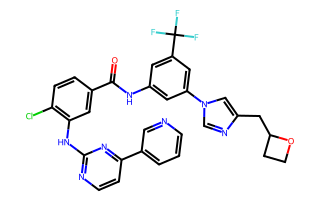

In [ ]:
# @title 4. Interactive Target Molecule Sketcher (JSME) + Multi-Identifier Resolver
import re
import urllib.parse
import requests
import IPython
from google.colab import output
from rdkit import Chem
from rdkit.Chem import Draw

# 1. Chemical Identifier Resolver (SMILES, InChI, InChIKey, PubChem CID, DrugBank, ChEMBL, CAS, Name)
def _fetch_pubchem_smiles(namespace, identifier):
    """Queries PubChem PUG-REST for Canonical/Connectivity SMILES."""
    encoded = urllib.parse.quote(str(identifier).strip())
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/{namespace}/{encoded}/property/CanonicalSMILES,ConnectivitySMILES/JSON"
    resp = requests.get(url, timeout=8)
    if resp.status_code == 200:
        props = resp.json().get("PropertyTable", {}).get("Properties", [])
        if props:
            p = props[0]
            return p.get("CanonicalSMILES") or p.get("ConnectivitySMILES") or p.get("SMILES")
    return None

def _resolve_chemical_identifier(query_str):
    """Resolves SMILES, InChI, InChIKey, PubChem CID, DrugBank ID, ChEMBL ID, CAS, or Drug Name."""
    q = (query_str or "").strip()
    if not q:
        return None, "Empty input"

    # A. Local RDKit Check: InChI string
    if q.startswith("InChI="):
        mol = Chem.MolFromInchi(q)
        if mol:
            return Chem.MolToSmiles(mol), "InChI (RDKit)"

    # B. Local RDKit Check: Direct SMILES (skip if it looks like a pure number/CID or word name)
    if not q.isdigit() and not re.match(r"^(DB\d+|CHEMBL\d+|[A-Z]{14}-[A-Z]{10}-[A-Z])$", q, re.I):
        mol = Chem.MolFromSmiles(q)
        if mol and mol.GetNumAtoms() > 0:
            return Chem.MolToSmiles(mol), "SMILES (RDKit)"

    # C. InChIKey (27 chars: 14-10-1)
    if re.match(r"^[A-Z]{14}-[A-Z]{10}-[A-Z]$", q, re.I):
        smi = _fetch_pubchem_smiles("inchikey", q.upper())
        if smi:
            return smi, f"InChIKey ({q.upper()})"

    # D. PubChem CID (handles '54732242', 'CID:54732242', 'PubChem CID 54732242', etc.)
    cid_match = re.match(r"^(?:pubchem[\s_-]*)?(?:cid[:=\s_-]*)?(\d+)$", q, re.I)
    if cid_match:
        cid = cid_match.group(1)
        smi = _fetch_pubchem_smiles("cid", cid)
        if smi:
            return smi, f"PubChem CID ({cid})"

    # E. ChEMBL ID (e.g., CHEMBL1234)
    if re.match(r"^CHEMBL\d+$", q, re.I):
        chembl_id = q.upper()
        try:
            r = requests.get(f"https://www.ebi.ac.uk/chembl/api/data/molecule/{chembl_id}.json", timeout=8)
            if r.status_code == 200:
                structs = r.json().get("molecule_structures") or {}
                smi = structs.get("canonical_smiles")
                if smi:
                    return smi, f"ChEMBL ({chembl_id})"
        except Exception:
            pass
        smi = _fetch_pubchem_smiles("name", chembl_id)
        if smi:
            return smi, f"ChEMBL via PubChem ({chembl_id})"

    # F. DrugBank ID (e.g., DB04868) -> PubChem Registry / Name / UniChem fallback
    if re.match(r"^DB\d{5}$", q, re.I):
        db_id = q.upper()
        smi = _fetch_pubchem_smiles("xref/RegistryID", db_id) or _fetch_pubchem_smiles("name", db_id)
        if smi:
            return smi, f"DrugBank ({db_id})"
        # Fallback via EBI UniChem API (DrugBank source ID = 2 -> ChEMBL source ID = 1)
        try:
            u_resp = requests.get(f"https://www.ebi.ac.uk/unichem/rest/src_compound_id/{db_id}/2/1", timeout=8)
            if u_resp.status_code == 200 and u_resp.json():
                chembl_hit = u_resp.json()[0].get("src_compound_id")
                if chembl_hit:
                    return _resolve_chemical_identifier(chembl_hit)
        except Exception:
            pass

    # G. Generic Drug Name, Synonym, or CAS Number -> PubChem Name Lookup + NCI CACTUS fallback
    smi = _fetch_pubchem_smiles("name", q)
    if smi:
        return smi, f"PubChem Name/Registry ('{q}')"

    try:
        cactus_url = f"https://cactus.nci.nih.gov/chemical/structure/{urllib.parse.quote(q)}/smiles"
        c_resp = requests.get(cactus_url, timeout=8)
        if c_resp.status_code == 200 and c_resp.text.strip():
            first_line = c_resp.text.strip().splitlines()[0].strip()
            if Chem.MolFromSmiles(first_line):
                return first_line, f"NCI CACTUS ('{q}')"
    except Exception:
        pass

    return None, f"Could not resolve identifier: '{q}'"

# 2. Colab Callbacks for Lookup, Atom-Locking & Custom Lab Stock
def _resolve_frozen_atoms(raw_mol, canon_mol, frozen_indices=None):
    """Maps JSME atom-starred maps, atom index lists, or SMARTS substructures onto canonical 0-based atom indices."""
    locked = []
    locked_smarts = None
    n_atoms = canon_mol.GetNumAtoms() if canon_mol is not None else 0

    # A. Detect starred/atom-mapped atoms directly from JSME SMILES if present
    if raw_mol is not None and canon_mol is not None and hasattr(raw_mol, "GetAtoms"):
        starred_raw = [a.GetIdx() for a in raw_mol.GetAtoms() if a.GetAtomMapNum() > 0]
        if starred_raw:
            unmapped_copy = Chem.Mol(raw_mol)
            for a in unmapped_copy.GetAtoms():
                a.SetAtomMapNum(0)
            match = canon_mol.GetSubstructMatch(unmapped_copy)
            if match:
                locked.extend(match[i] for i in starred_raw if i < len(match))

    # B. Parse explicit frozen_indices (list/tuple of ints, comma-separated ints, or SMARTS/SMILES pattern)
    if isinstance(frozen_indices, (list, tuple, set)):
        raw_ints = [int(x) for x in frozen_indices]
        if raw_ints and all(0 <= i < n_atoms for i in raw_ints):
            locked.extend(raw_ints)
        elif raw_ints and all(1 <= i <= n_atoms for i in raw_ints):
            locked.extend(i - 1 for i in raw_ints)
    elif isinstance(frozen_indices, str) and frozen_indices.strip():
        spec = frozen_indices.strip()
        if re.match(r"^[\d,\s]+$", spec):
            raw_ints = [int(tok) for tok in re.split(r"[,\s]+", spec) if tok.strip()]
            if raw_ints and all(0 <= i < n_atoms for i in raw_ints):
                locked.extend(raw_ints)
            elif raw_ints and all(1 <= i <= n_atoms for i in raw_ints):
                locked.extend(i - 1 for i in raw_ints)
            else:
                locked.extend(i for i in raw_ints if 0 <= i < n_atoms)
        else:
            pat = Chem.MolFromSmarts(spec)
            if pat is None:
                pat = Chem.MolFromSmiles(spec)
            if pat is not None and canon_mol is not None:
                match = canon_mol.GetSubstructMatch(pat)
                if match:
                    locked.extend(match)
                    locked_smarts = spec

    return sorted(set(locked)), locked_smarts

def _lookup_and_set_target(query_str):
    smi, source_label = _resolve_chemical_identifier(query_str)
    if not smi:
        return IPython.display.JSON({"error": source_label})

    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return IPython.display.JSON({"error": f"Resolved invalid SMILES from {source_label}: {smi}"})

    canon_smiles = Chem.MolToSmiles(mol)
    if "finder" in globals():
        finder.target_smiles = canon_smiles
        finder.CustomFrozenAtoms = []
        finder.CustomFrozenSmarts = None

    return IPython.display.JSON({
        "smiles": canon_smiles,
        "source": source_label,
    })

def _set_target_smiles(smiles_str, frozen_indices=None):
    smiles_str = (smiles_str or "").strip()
    raw_mol = Chem.MolFromSmiles(smiles_str)
    if raw_mol is None or not smiles_str:
        print(f"⚠️ Invalid or empty structure: '{smiles_str}'")
        return

    clean_mol = Chem.Mol(raw_mol)
    if hasattr(clean_mol, "GetAtoms"):
        for atom in clean_mol.GetAtoms():
            if atom.GetAtomMapNum() > 0:
                atom.SetAtomMapNum(0)

    canon_smiles = Chem.MolToSmiles(clean_mol)
    canon_mol = Chem.MolFromSmiles(canon_smiles) or clean_mol
    locked_atoms, locked_smarts = _resolve_frozen_atoms(raw_mol, canon_mol, frozen_indices=frozen_indices)

    if "finder" in globals():
        finder.target_smiles = canon_smiles
        finder.CustomFrozenAtoms = locked_atoms
        finder.CustomFrozenSmarts = locked_smarts

    if locked_atoms:
        print(f"✅ Successfully set finder.target_smiles = '{canon_smiles}' | 🔒 Locked atom indices: {locked_atoms}")
        display(Draw.MolToImage(canon_mol, size=(320, 200), highlightAtoms=locked_atoms))
    else:
        print(f"✅ Successfully set finder.target_smiles = '{canon_smiles}'")
        display(Draw.MolToImage(canon_mol, size=(320, 200)))

def _load_custom_stock_callback(raw_text, stock_name="lab_inventory"):
    text = (raw_text or "").strip()
    if not text:
        return IPython.display.JSON({"error": "Please paste or upload at least one SMILES string."})

    parsed_smiles = []
    header_skip = {"smiles", "canonical_smiles", "smi", "name", "id", "catalog_id", "amount", "inchikey", "inchi_key"}
    for line in text.splitlines():
        row = line.strip()
        if not row or row.startswith("#"):
            continue
        cols = [c.strip().strip('"').strip("'") for c in re.split(r"[,;\t]", row) if c.strip()]
        if not cols:
            continue
        if cols[0].lower() in header_skip and len(cols) >= 1:
            continue
        chosen = None
        for col in cols:
            if col.lower() in header_skip:
                continue
            m = Chem.MolFromSmiles(col)
            if m is not None and m.GetNumAtoms() > 0:
                chosen = col
                break
        parsed_smiles.append(chosen if chosen is not None else cols[0])

    try:
        info = register_custom_lab_stock(parsed_smiles, stock_name=stock_name or "lab_inventory")
        return IPython.display.JSON(info)
    except Exception as e:
        return IPython.display.JSON({"error": str(e)})

output.register_callback("notebook.resolve_identifier", _lookup_and_set_target)
output.register_callback("notebook.set_target_smiles", _set_target_smiles)
output.register_callback("notebook.load_custom_stock", _load_custom_stock_callback)

# 3. Render Interactive Identifier Search + JSME Molecule Sketcher + Constraints Drawer
html_code = """
<div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; width: 680px;">
  <div style="margin-bottom: 6px; font-weight: 600; font-size: 14px; color: #202124;">
    🔎 1. Search by Chemical Identifier (Drug Name, PubChem CID, DrugBank ID, ChEMBL ID, InChIKey, CAS, or SMILES):
  </div>
  <div style="display: flex; gap: 8px; margin-bottom: 6px;">
    <input id="chem-id-input" type="text"
           placeholder="e.g., Febuxostat | DB04868 | 134018 | CHEMBL175691 | BAXJSDGLLature... | CAS 144060-53-7"
           style="flex: 1; padding: 8px 10px; font-size: 13px; border: 1px solid #ccc; border-radius: 5px;" />
    <button id="lookup-id-btn"
            style="background-color: #1a73e8; color: white; border: none; padding: 8px 14px;
                   font-size: 13px; font-weight: 600; border-radius: 5px; cursor: pointer; white-space: nowrap;">
      🔍 Fetch Structure
    </button>
  </div>
  <div style="display: flex; gap: 6px; flex-wrap: wrap; align-items: center; margin-bottom: 10px; font-size: 12px; color: #5f6368;">
    <span>Quick examples:</span>
    <button onclick="quickLookup('Febuxostat')" style="border:1px solid #dadce0; background:#f8f9fa; border-radius:12px; padding:2px 9px; cursor:pointer; font-size:11px;">Name: Febuxostat</button>
    <button onclick="quickLookup('DB04868')" style="border:1px solid #dadce0; background:#f8f9fa; border-radius:12px; padding:2px 9px; cursor:pointer; font-size:11px;">DrugBank: DB04868 (Nilotinib)</button>
    <button onclick="quickLookup('5479530')" style="border:1px solid #dadce0; background:#f8f9fa; padding:2px 9px; border-radius:12px; cursor:pointer; font-size:11px;">PubChem CID: 5479530 (Naldemedine)</button>
    <button onclick="quickLookup('KTUFNOKKBVMGRW-UHFFFAOYSA-N')" style="border:1px solid #dadce0; background:#f8f9fa; padding:2px 9px; border-radius:12px; cursor:pointer; font-size:11px;">InChIKey: Imatinib</button>
  </div>

  <div style="margin-bottom: 6px; font-weight: 600; font-size: 14px; color: #202124;">
    ✏️ 2. Or Draw / Edit Structure Directly in the Sketcher (use ★ tool to pin/lock atoms):
  </div>
  <div id="jsme_container" style="width: 680px; height: 400px; border: 1px solid #ccc; border-radius: 6px;"></div>

  <div style="margin-top: 10px; display: flex; align-items: center; gap: 10px; width: 680px;">
    <input id="manual-smiles" type="text" placeholder="Active SMILES string..."
           style="flex: 1; padding: 8px; font-family: monospace; font-size: 13px; border: 1px solid #ccc; border-radius: 4px;"
           value="Cc1nc(C2=CC=C(OCC(C)C)C(C#N)=C2)sc1C(=O)O" />
    <button id="save-smiles-btn" style="background-color: #28a745; color: white; border: none;
            padding: 9px 16px; font-size: 13px; font-weight: bold; border-radius: 5px; cursor: pointer; white-space: nowrap;">
      ✅ Set as finder.target_smiles
    </button>
  </div>
  <div id="smiles-status" style="margin-top: 6px; font-family: monospace; font-size: 13px; color: #155724;"></div>

  <details style="margin-top: 10px; border: 1px solid #dadce0; border-radius: 6px; padding: 8px 12px; background: #f8f9fa;">
    <summary style="cursor: pointer; font-weight: 600; font-size: 13px; color: #202124;">
      ⚙️ 3. Optional Constraints: Substructure Atom-Locking &amp; Custom Lab Inventory Stock
    </summary>
    <div style="margin-top: 10px; display: flex; flex-direction: column; gap: 10px; font-size: 12px;">
      <div>
        <label style="font-weight: 600; color: #3c4043; display: block; margin-bottom: 4px;">
          🔒 Frozen Atom Indices / SMARTS Substructure to Keep Intact:
        </label>
        <input id="frozen-atoms-input" type="text"
               placeholder="Lock core ring SMARTS or atom indices (e.g., c1ncsc1 or 0,1,2,3)"
               style="width: 100%; box-sizing: border-box; padding: 6px 8px; font-family: monospace; font-size: 12px; border: 1px solid #ccc; border-radius: 4px;" />
      </div>
      <div>
        <label style="font-weight: 600; color: #3c4043; display: block; margin-bottom: 4px;">
          🧪 Custom Lab Inventory SMILES ("What's in My Lab Freezer?" CSV / List):
        </label>
        <textarea id="custom-stock-input" rows="3"
                  placeholder="Paste one SMILES per line or upload a CSV of in-house building blocks..."
                  style="width: 100%; box-sizing: border-box; padding: 6px 8px; font-family: monospace; font-size: 12px; border: 1px solid #ccc; border-radius: 4px;"></textarea>
        <div style="margin-top: 6px; display: flex; align-items: center; gap: 8px; flex-wrap: wrap;">
          <input id="custom-stock-file" type="file" accept=".csv,.txt,.smi" style="font-size: 12px;" />
          <button id="load-stock-btn" type="button"
                  style="background-color: #1a73e8; color: white; border: none; padding: 6px 12px; font-size: 12px; font-weight: 600; border-radius: 4px; cursor: pointer;">
            📦 Load Lab Stock
          </button>
          <span id="custom-stock-status" style="font-family: monospace; font-size: 12px; color: #155724;"></span>
        </div>
      </div>
    </div>
  </details>
</div>

<script>
function initJSME() {
  if (typeof JSApplet !== "undefined") {
    window.jsmeApplet = new JSApplet.JSME("jsme_container", "680px", "400px", {"options": "star"});
    const defaultSmiles = document.getElementById("manual-smiles").value;
    window.jsmeApplet.readGenericMolecularInput(defaultSmiles);
    window.jsmeApplet.setCallBack("AfterStructureModified", function(event) {
      const s = window.jsmeApplet.smiles();
      if (s) document.getElementById("manual-smiles").value = s;
    });
  }
}

window.jsmeOnLoad = function() { initJSME(); };

if (!document.getElementById("jsme-script")) {
  const script = document.createElement("script");
  script.id = "jsme-script";
  script.src = "https://jsme-editor.github.io/dist/jsme/jsme.nocache.js";
  document.head.appendChild(script);
} else {
  setTimeout(initJSME, 300);
}

async function resolveIdentifier() {
  const query = document.getElementById("chem-id-input").value.trim();
  const statusEl = document.getElementById("smiles-status");
  const lookupBtn = document.getElementById("lookup-id-btn");
  if (!query) return;

  statusEl.style.color = "#1a73e8";
  statusEl.innerText = "⏳ Resolving '" + query + "' across RDKit, PubChem, ChEMBL, DrugBank & CACTUS...";
  lookupBtn.disabled = true;

  try {
    const res = await google.colab.kernel.invokeFunction("notebook.resolve_identifier", [query], {});
    const data = res.data["application/json"];
    if (data.error) {
      statusEl.style.color = "#d93025";
      statusEl.innerText = "⚠️ " + data.error;
    } else {
      document.getElementById("manual-smiles").value = data.smiles;
      if (window.jsmeApplet) {
        window.jsmeApplet.readGenericMolecularInput(data.smiles);
      }
      statusEl.style.color = "#155724";
      statusEl.innerText = "✅ Resolved via " + data.source + " → finder.target_smiles = '" + data.smiles + "'";
    }
  } catch (err) {
    statusEl.style.color = "#d93025";
    statusEl.innerText = "⚠️ Kernel communication error: " + err;
  } finally {
    lookupBtn.disabled = false;
  }
}

function quickLookup(val) {
  document.getElementById("chem-id-input").value = val;
  resolveIdentifier();
}

document.getElementById("lookup-id-btn").onclick = resolveIdentifier;
document.getElementById("chem-id-input").addEventListener("keydown", function(e) {
  if (e.key === "Enter") {
    e.preventDefault();
    resolveIdentifier();
  }
});

// Sync manual SMILES input box changes to JSME canvas on Enter or blur
document.getElementById("manual-smiles").addEventListener("change", function(e) {
  const smi = e.target.value.trim();
  if (smi && window.jsmeApplet) {
    window.jsmeApplet.readGenericMolecularInput(smi);
  }
});

document.getElementById("save-smiles-btn").onclick = function() {
  const statusEl = document.getElementById("smiles-status");
  const manualInput = document.getElementById("manual-smiles").value.trim();
  const jsmeSmiles = (window.jsmeApplet && window.jsmeApplet.smiles()) ? window.jsmeApplet.smiles().trim() : "";
  const frozenSpec = document.getElementById("frozen-atoms-input").value.trim();

  // Prefer JSME atom-mapped SMILES if user starred atoms on canvas, otherwise manual input
  const smiles = (jsmeSmiles && jsmeSmiles.indexOf(":") !== -1) ? jsmeSmiles : (manualInput || jsmeSmiles);
  if (window.jsmeApplet && smiles) {
    window.jsmeApplet.readGenericMolecularInput(smiles);
  }
  statusEl.style.color = "#155724";
  statusEl.innerText = "Setting finder.target_smiles = " + smiles + (frozenSpec ? " (lock: " + frozenSpec + ")" : "") + " ...";
  google.colab.kernel.invokeFunction("notebook.set_target_smiles", [smiles, frozenSpec], {});
};

document.getElementById("custom-stock-file").addEventListener("change", function(e) {
  const file = e.target.files && e.target.files[0];
  if (!file) return;
  const reader = new FileReader();
  reader.onload = function(evt) {
    document.getElementById("custom-stock-input").value = evt.target.result || "";
  };
  reader.readAsText(file);
});

document.getElementById("load-stock-btn").onclick = async function() {
  const rawText = document.getElementById("custom-stock-input").value.trim();
  const stockStatus = document.getElementById("custom-stock-status");
  const loadBtn = document.getElementById("load-stock-btn");
  if (!rawText) {
    stockStatus.style.color = "#d93025";
    stockStatus.innerText = "⚠️ Paste SMILES or select a CSV file first.";
    return;
  }
  loadBtn.disabled = true;
  stockStatus.style.color = "#1a73e8";
  stockStatus.innerText = "⏳ Loading custom lab stock...";
  try {
    const res = await google.colab.kernel.invokeFunction("notebook.load_custom_stock", [rawText], {});
    const data = res.data["application/json"];
    if (data.error) {
      stockStatus.style.color = "#d93025";
      stockStatus.innerText = "⚠️ " + data.error;
    } else {
      stockStatus.style.color = "#155724";
      stockStatus.innerText = "✅ Loaded " + data.loaded_count + " compounds into '" + data.stock_name + "'";
    }
  } catch (err) {
    stockStatus.style.color = "#d93025";
    stockStatus.innerText = "⚠️ Kernel error: " + err;
  } finally {
    loadBtn.disabled = false;
  }
};
</script>
"""
IPython.display.display(IPython.display.HTML(html_code))

### Cell 5A: Configure Search Settings
Displays an `ipywidgets` control panel to customize the retrosynthesis search and route ranking:
- **Search Parameters:** Algorithm (`Retro*` vs. `MCTS`), max synthetic steps, time limit, iteration limit, return-first-solved toggle, template probability cutoff, and max routes to extract.
- **Chemistry & Scoring:** Route ranking profile (`balanced`, `medchem_fast`, `process_scaleup`, `green_safe`), target synthesis scale (g), reaction type exclusion checkboxes, and a toggle for the Gemini AI classifier.
- Clicking **Save Search Configuration and Route Rank Settings** updates `RETRO_SEARCH_PARAMS` and applies them to `finder.config`.

### ⚙️ Quick Guide to Search Settings


## ⚖️ MCTS vs. Retro*: Choosing a Search Algorithm

When configuring retrosynthesis engines like [AiZynthFinder](https://github.com/MolecularAI/aizynthfinder/), selecting the right search algorithm dictates how the AI explores retrosynthetic pathways:

| Feature | MCTS (Monte Carlo Tree Search) | Retro* (AND-OR Tree Search) |
| :--- | :--- | :--- |
| **Search Strategy** | Stochastic, rollout-based sampling guided by UCB/PUCT exploration-exploitation. | Deterministic best-first search guided by a learned synthetic cost heuristic. |
| **Route Diversity** | **High.** Because of its exploration bonus, MCTS naturally branches out and discovers structurally distinct, alternative synthetic strategies given enough iterations. | **Lower.** Focuses heavily on converging rapidly onto the single lowest-cost path first. |
| **Speed to First Solution** | Moderate; spends iterations sampling broadly before committing deep down one branch. | **Fast;** greedily follows the steepest gradient toward in-stock building blocks. |
| **Best Use Case** | Complex targets where the obvious disconnection fails, or when you want multiple distinct route options (e.g., comparing convergent vs. linear routes). | Rapid feasibility checks, high-throughput virtual library screening, and finding the shortest possible route quickly. |


#### Explanations:

* **Search Algorithm:** Chooses how the AI explores possible syntheses. **Retro\*** is usually faster and focuses straight on the most promising path; **MCTS** explores more broadly and can find a wider variety of routes if given more time.
* **Route Ranking Profile:** Decides how finished routes are scored and sorted:
  * **balanced:** Equal mix of step count, stock availability, and feasibility.
  * **medchem_fast:** Favors the shortest routes to make analogs quickly.
  * **process_scaleup:** Penalizes dangerous reagents and hard-to-scale steps.
  * **green_safe:** Prioritizes safer, more environmentally friendly solvents and conditions.
* **Max Synthetic Steps:** The maximum number of reaction steps allowed in a route. Lower numbers (3–5) finish faster; higher numbers (7–12) are needed for complex molecules.
* **Search Time Limit (sec):** The maximum time the search is allowed to run before stopping automatically.
* **Iteration Limit:** The maximum number of search cycles the AI will perform. Higher numbers let it explore more options, while lower numbers give quicker results.
* **Return First Solved:** When ticked, the search stops the moment it finds *one* complete route using in-stock starting materials (great for a fast check). Untick it to keep searching for alternative routes.
* **Template Probability Cutoff:** Controls how "creative" the AI is with reactions. Lower values (0.85–0.95) stick to common, reliable reactions and run faster; higher values (0.98–0.999) allow rarer disconnections.
* **Max Top Routes to Extract:** How many of the best-ranked routes to display after the search finishes.
* **Target Synthesis Scale (g):** How much final product you want to make. This scales the reagent quantities and makes hazard warnings stricter for larger batches.
* **Exclude Reaction Types:** Tick any reactions you want to avoid (e.g., toxic reagents or chemistry you don't want to run in the lab) to filter them out of the results.
* **Gemini AI Classifier:** When enabled (**True**), uses Gemini alongside RDKit to name reactions, suggest realistic lab conditions, and flag greener solvent swaps. Set to **False** for faster, offline RDKit-only labeling.

*Click **Save Search Configuration and Route Rank Settings** after making changes, then run **Cell 5B** to start the search.*

### Search Configuration


In [ ]:
# @title 5A. Configure Search Settings
from IPython.display import display
import ipywidgets as widgets

def build_search_settings_ui():
    style = {"description_width": "240px"}
    layout = widgets.Layout(width="520px")

    # Preserve previously saved values if re-running the cell
    prev = globals().get("RETRO_SEARCH_PARAMS", {})

    w_algo = widgets.Dropdown(
        options=[
            ("MCTS (Monte Carlo Tree Search)", "aizynthfinder.search.mcts.search.MctsSearchTree"),
            ("Retro* (AND-OR Tree Search)", "aizynthfinder.search.retrostar.search_tree.SearchTree"),
        ],
        value=prev.get("search_algorithm", "aizynthfinder.search.mcts.search.MctsSearchTree"),
        description="Search Algorithm:",
        style=style,
        layout=layout,
    )
    w_rank = widgets.Dropdown(
        options=["balanced", "medchem_fast", "process_scaleup", "green_safe"],
        value=prev.get("ranking_mode", "balanced"),
        description="Route Ranking Profile:",
        style=style,
        layout=layout,
    )
    w_steps = widgets.Dropdown(
        options=list(range(1, 13)),
        value=prev.get("max_transforms", 6),
        description="Max Synthetic Steps:",
        style=style,
        layout=layout,
    )
    w_time = widgets.Dropdown(
        options=[15, 30, 60, 120, 180, 300, 600, 1200],
        value=prev.get("time_limit", 120),
        description="Search Time Limit (sec):",
        style=style,
        layout=layout,
    )
    w_iter = widgets.Dropdown(
        options=[10, 25, 50, 100, 200, 300, 500, 1000, 1500, 2000],
        value=prev.get("iteration_limit", 100),
        description="Iteration Limit:",
        style=style,
        layout=layout,
    )
    w_first = widgets.Checkbox(
        value=prev.get("return_first", True),
        description="Return First Solved (Stop at first route)",
        style=style,
        layout=layout,
    )
    w_cutoff = widgets.Dropdown(
        options=[0.50, 0.75, 0.85, 0.90, 0.95, 0.98, 0.995, 0.999, 1.00],
        value=prev.get("cutoff_cumulative", 0.95),
        description="Template Probability Cutoff:",
        style=style,
        layout=layout,
    )
    w_routes = widgets.Dropdown(
        options=[1, 3, 5, 10, 15, 20, 25],
        value=prev.get("max_routes_to_extract", 10),
        description="Max Top Routes to Extract:",
        style=style,
        layout=layout,
    )
    w_scale = widgets.Dropdown(
        options=[0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0, 1000.0],
        value=prev.get("target_scale_grams", 1.0),
        description="Target Synthesis Scale (g):",
        style=style,
        layout=layout,
    )

    reaction_options = [
        ("Suzuki-Miyaura Cross-Coupling", "Suzuki-Miyaura"),
        ("Amide Bond Coupling", "Amide Bond"),
        ("Buchwald-Hartwig Amination", "Buchwald-Hartwig"),
        ("Reductive Amination", "Reductive Amination"),
        ("Ester Hydrolysis / Saponification", "Ester Hydrolysis"),
        ("N-Boc Deprotection", "N-Boc Deprotection"),
        ("N-Cbz Deprotection", "N-Cbz Deprotection"),
        ("Schotten-Baumann Acylation", "Schotten-Baumann"),
        ("Sulfonamide Formation", "Sulfonamide Formation"),
        ("Williamson Ether Synthesis", "Williamson Ether"),
        ("Mitsunobu Etherification", "Mitsunobu"),
        ("Sonogashira Cross-Coupling", "Sonogashira"),
        ("Stille Cross-Coupling", "Stille"),
        ("Mizoroki-Heck Reaction", "Heck"),
        ("Chan-Lam Coupling", "Chan-Lam"),
        ("Hantzsch Thiazole Synthesis", "Hantzsch Thiazole"),
        ("CuAAC 'Click' Cycloaddition", "Click"),
        ("Azide-Nitrile Cycloaddition", "Azide-Nitrile"),
        ("Nitro Reduction to Amine", "Nitro Reduction"),
        ("Silyl Ether Deprotection", "Silyl Ether Deprotection"),
        ("Grignard Addition", "Grignard Addition"),
        ("Swern Oxidation", "Swern Oxidation"),
        ("Friedel-Crafts Acylation", "Friedel-Crafts Acylation"),
        ("Epoxide Ring Opening", "Epoxide Opening"),
    ]

    prev_excl = set(prev.get("exclude_reaction_names", []))
    w_excl_boxes = {
        val: widgets.Checkbox(
            value=(val in prev_excl),
            description=label,
            layout=widgets.Layout(width="480px"),
        )
        for label, val in reaction_options
    }

    # Expanded viewing height for the scrollable box
    checkboxes_vbox = widgets.VBox(
        list(w_excl_boxes.values()),
        layout=widgets.Layout(
            max_height="320px",
            overflow_y="auto",
            border="1px solid #ccc",
            padding="5px",
        ),
    )

    # Unrestricted text input for typing in any custom reaction names
    w_custom_excl = widgets.Text(
        value=", ".join([x for x in prev_excl if x not in w_excl_boxes]),
        placeholder="e.g. Ozonolysis, Wittig, Halogenation (comma-separated)",
        description="Custom Banned Reactions:",
        style=style,
        layout=layout,
    )

    w_excl_container = widgets.VBox(
        [
            widgets.HTML("<b>Exclude Reaction Types (Check boxes or type custom tokens):</b>", style=style),
            checkboxes_vbox,
            widgets.HTML("<div style='font-size:11px; color:#555; margin-top:4px;'>Type additional reactions above separated by commas:</div>", style=style),
            w_custom_excl,
        ],
        layout=widgets.Layout(margin="10px 0px 10px 0px"),
    )

    w_gem = widgets.Dropdown(
        options=[
            ("True (Gemini AI + RDKit)", True),
            ("False (Local RDKit only)", False),
        ],
        value=prev.get("use_gemini", True),
        description="Gemini AI Classifier:",
        style=style,
        layout=layout,
    )
    save_btn = widgets.Button(
        description="Save Search Configuration and Route Rank Settings",
        button_style="success",
        icon="check",
        layout=widgets.Layout(width="520px", height="38px", margin="10px 0px 6px 0px"),
    )
    status_banner = widgets.HTML(value="")

    def apply_settings(_=None):
        global search_algorithm, ranking_mode, max_transforms, time_limit
        global iteration_limit, return_first, cutoff_cumulative
        global max_routes_to_extract, target_scale_grams
        global exclude_reactions_csv, excluded_list
        global use_gemini_classifier, USE_GEMINI_CLASSIFIER, RETRO_SEARCH_PARAMS

        search_algorithm = w_algo.value
        ranking_mode = w_rank.value
        max_transforms = int(w_steps.value)
        time_limit = int(w_time.value)
        iteration_limit = int(w_iter.value)
        return_first = bool(w_first.value)
        cutoff_cumulative = float(w_cutoff.value)
        max_routes_to_extract = int(w_routes.value)
        target_scale_grams = float(w_scale.value)

        # Collect checked options
        excluded_list = [key for key, cb in w_excl_boxes.items() if cb.value]

        # Append any custom typed-in reaction names/tokens
        if w_custom_excl.value.strip():
            custom_tokens = [t.strip() for t in w_custom_excl.value.split(",") if t.strip()]
            for token in custom_tokens:
                if token not in excluded_list:
                    excluded_list.append(token)

        exclude_reactions_csv = ", ".join(excluded_list)
        use_gemini_classifier = bool(w_gem.value)
        USE_GEMINI_CLASSIFIER = use_gemini_classifier

        RETRO_SEARCH_PARAMS = {
            "search_algorithm": search_algorithm,
            "ranking_mode": ranking_mode,
            "max_transforms": max_transforms,
            "time_limit": time_limit,
            "iteration_limit": iteration_limit,
            "return_first": return_first,
            "cutoff_cumulative": cutoff_cumulative,
            "max_routes_to_extract": max_routes_to_extract,
            "target_scale_grams": target_scale_grams,
            "exclude_reaction_names": excluded_list,
            "use_gemini": use_gemini_classifier,
        }

        if "finder" in globals() and finder is not None:
            finder.config.search.algorithm = search_algorithm
            finder.config.search.max_transforms = max_transforms
            finder.config.search.time_limit = time_limit
            finder.config.search.iteration_limit = iteration_limit
            finder.config.search.return_first = return_first
            if hasattr(finder.config.search, "cutoff_cumulative"):
                finder.config.search.cutoff_cumulative = cutoff_cumulative
            if hasattr(finder.config, "expansion_policy") and hasattr(
                finder.config.expansion_policy, "cutoff_cumulative"
            ):
                finder.config.expansion_policy.cutoff_cumulative = cutoff_cumulative
            if hasattr(finder.config, "post_processing"):
                finder.config.post_processing.max_routes = max_routes_to_extract

        algo_label = "MCTS" if "mcts" in search_algorithm.lower() else "Retro*"
        excl_label = exclude_reactions_csv if exclude_reactions_csv else "None"
        gem_label = "Gemini + RDKit" if use_gemini_classifier else "RDKit Only"

        status_banner.value = (
            "<div style='padding:8px 12px; background:#e6f4ea; border:1px solid #34a853; "
            "border-radius:6px; color:#137333; font-family:monospace; font-size:12px;'>"
            f"✅ <b>Settings saved & applied:</b> {algo_label} | profile={ranking_mode} | "
            f"steps={max_transforms} | time={time_limit}s | iterations={iteration_limit} | "
            f"return_first={return_first} | cutoff={cutoff_cumulative} | "
            f"max_routes={max_routes_to_extract} | scale={target_scale_grams}g | "
            f"classifier={gem_label} | excluded={excl_label}"
            "</div>"
        )

    save_btn.on_click(apply_settings)
    apply_settings()

    return widgets.VBox([
        w_algo,
        w_rank,
        w_steps,
        w_time,
        w_iter,
        w_first,
        w_cutoff,
        w_routes,
        w_scale,
        w_excl_container,
        w_gem,
        save_btn,
        status_banner,
    ])

display(build_search_settings_ui())

### Cell 5B: Launch Retrosynthesis Search
Defines the main retrosynthesis execution pipeline and displays the **Run Retrosynthesis Search** button:
- **Search & Classification:** Runs `finder.tree_search()` with a live elapsed-time progress bar, builds the resulting routes, and classifies each step via Gemini and/or RDKit.
- **Filtering & Scoring:** Filters out routes containing banned reactions or violating substructure locks, tags starting materials (`Lab Stock`, `ZINC Stock`, or `Not in Stock`), computes multi-objective composite scores, and identifies Pareto-optimal routes.
- **Output & ELN Export:** Renders HTML/SVG route cards, saves results to `LATEST_RETRO_RESULTS`, and provides `generate_eln_markdown()` to export scaled stoichiometry tables for any route.

In [ ]:
# @title 5B. Launch Retrosynthesis Search { display-mode: "form" }
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
from rdkit import Chem
from rdkit.Chem import Descriptors


def compute_composite_route_score(route, mode="balanced"):
    """Multi-objective route scoring across balanced, medchem_fast, process_scaleup, and green_safe."""
    state_score = float(route.get("state_score", 0.0))
    steps = max(1, int(route.get("step_count", 1)))
    safety_norm = float(route.get("avg_safety_score", 4.0)) / 5.0
    step_score = max(0.0, 1.0 - (steps - 1) * 0.10)
    risk_penalty = min(0.4, 0.08 * int(route.get("selectivity_risk_count", 0)))
    sm = route.get("starting_materials", {})
    stock_frac = (sm.get("in_stock_count", 0) / max(1, sm.get("total_leaves", 1)))

    weights = {
        "balanced":        (0.35, 0.25, 0.20, 0.20),
        "medchem_fast":    (0.25, 0.45, 0.10, 0.20),
        "process_scaleup": (0.25, 0.15, 0.35, 0.25),
        "green_safe":      (0.20, 0.15, 0.45, 0.20),
    }.get(mode, (0.35, 0.25, 0.20, 0.20))

    w_state, w_step, w_safe, w_stock = weights
    score = (
        w_state * state_score
        + w_step * step_score
        + w_safe * safety_norm
        + w_stock * stock_frac
        - risk_penalty
    )
    return round(max(0.0, min(1.0, score)), 4)


def generate_eln_markdown(route_idx=1, target_scale_grams=1.0, assumed_step_yield=0.80, results=None):
    """Generates an ELN-ready Markdown report with scaled stoichiometry for a given 1-based route."""
    res = results or globals().get("LATEST_RETRO_RESULTS") or {}
    routes = res.get("routes", [])
    if not (1 <= int(route_idx) <= len(routes)):
        return f"Route #{route_idx} not found. Run the retrosynthesis search first."

    route = routes[int(route_idx) - 1]
    target_smi = res.get("target_smiles", "")
    t_mol = Chem.MolFromSmiles(target_smi) if target_smi else None
    t_mw = Descriptors.MolWt(t_mol) if t_mol else 300.0
    target_mmol = (float(target_scale_grams) * 1000.0) / max(1.0, t_mw)
    step_yield = max(0.05, min(1.0, float(assumed_step_yield)))
    steps = route.get("steps", [])
    n_steps = len(steps)

    lines = [
        f"## Route #{route_idx} — ELN Synthesis Protocol ({target_scale_grams:.2f} g Target Scale)",
        f"- **Target SMILES:** `{target_smi}` (MW: {t_mw:.2f} g/mol, {target_mmol:.2f} mmol)",
        f"- **Composite Score:** {route.get('composite_score', 0.0):.4f} | **State Score:** {route.get('state_score', 0.0):.4f} | **Solved:** {route.get('is_solved', False)}",
        f"- **Safety/Green Avg:** {route.get('avg_safety_score', 4.0):.1f}/5 | **Assumed Yield/Step:** {step_yield * 100:.0f}%",
        "",
    ]

    for idx, st in enumerate(steps, start=1):
        steps_remaining = n_steps - idx
        req_prod_mmol = target_mmol / (step_yield ** steps_remaining)
        req_react_mmol = req_prod_mmol / step_yield

        lines.append(f"### Step {idx}: {st.get('reaction_name', 'Reaction Step')}")
        lines.append(f"- **Forward SMILES:** `{st.get('forward_smiles', '')}`")
        lines.append(f"- **Typical Conditions:** {st.get('typical_conditions', 'Standard literature conditions')}")
        lines.append(f"- **Safety/Green Score:** {st.get('safety_green_score', 4)}/5")
        if st.get("selectivity_warning", "None") != "None":
            lines.append(f"- **Selectivity Warning:** {st['selectivity_warning']}")
        if st.get("protecting_group_note", "None") != "None":
            lines.append(f"- **Protecting Group Note:** {st['protecting_group_note']}")
        if st.get("greener_solvent_swap", "None") != "None":
            lines.append(f"- **Greener Solvent Swap:** {st['greener_solvent_swap']}")
        if st.get("stereochem_note", "Achiral / Racemic") != "Achiral / Racemic":
            lines.append(f"- **Stereochemistry:** {st['stereochem_note']}")

        fwd = st.get("forward_smiles", "")
        if ">>" in fwd:
            r_str, p_str = fwd.split(">>", 1)
            r_smis = [s.strip() for s in r_str.split(".") if s.strip()]
            lines.append("\n| Role | SMILES | MW (g/mol) | Equiv | mmol | Mass (g) |")
            lines.append("| :--- | :--- | :---: | :---: | :---: | :---: |")
            for r_i, rs in enumerate(r_smis):
                rm = Chem.MolFromSmiles(rs)
                rmw = Descriptors.MolWt(rm) if rm else 0.0
                eq = 1.0 if r_i == 0 else 1.2
                mmol = req_react_mmol * eq
                mass_g = (mmol * rmw) / 1000.0
                lines.append(f"| Reactant {r_i + 1} | `{rs}` | {rmw:.2f} | {eq:.1f} | {mmol:.2f} | {mass_g:.3f} |")
            pm = Chem.MolFromSmiles(p_str.strip())
            pmw = Descriptors.MolWt(pm) if pm else 0.0
            pmass = (req_prod_mmol * pmw) / 1000.0
            lines.append(f"| **Product** | `{p_str.strip()}` | {pmw:.2f} | — | {req_prod_mmol:.2f} | **{pmass:.3f}** |")
        lines.append("")

    return "\n".join(lines)


def run_retrosynthesis_pipeline(
    target_smiles,
    ranking_mode="balanced",
    max_transforms=6,
    time_limit=120,
    exclude_reaction_names=None,
    lock_substructure_smarts=None,
    target_scale_grams=1.0,
    use_gemini=True,
    render_output=True,
):
    """Runs AiZynthFinder, classifies steps (Gemini + RDKit), filters constraints, and ranks routes."""
    if not target_smiles:
        raise ValueError("No target molecule set. Resolve or draw a molecule in Cell 4 first.")

    finder.target_smiles = target_smiles
    finder.config.search.max_transforms = int(max_transforms)
    finder.config.search.time_limit = int(time_limit)

    algo_name = "MCTS" if "mcts" in str(finder.config.search.algorithm).lower() else "Retro*"
    if render_output:
        print(f"🔬 Running {algo_name} retrosynthesis for: {target_smiles}")

    import time, threading

    stop_timer = threading.Event()
    time_bar = widgets.IntProgress(
        value=0, min=0, max=int(time_limit),
        description="Time Limit:", bar_style="info",
        layout=widgets.Layout(width="420px"),
    )
    time_label = widgets.HTML(value=f"<b>0s elapsed | {int(time_limit)}s remaining</b>")

    if render_output:
        display(widgets.HBox([time_bar, time_label]))

        def _tick_timer():
            start = time.time()
            while not stop_timer.is_set():
                elapsed = int(time.time() - start)
                rem = max(0, int(time_limit) - elapsed)
                time_bar.value = min(elapsed, int(time_limit))
                time_label.value = f"<b>{elapsed}s elapsed | {rem}s remaining</b>"
                if rem == 0:
                    break
                stop_timer.wait(1.0)

        t_thread = threading.Thread(target=_tick_timer, daemon=True)
        t_thread.start()

    try:
        finder.tree_search(show_progress=render_output)
    finally:
        stop_timer.set()
        if render_output:
            time_bar.bar_style = "success"
            time_label.value = "<b>✅ Search complete — building & ranking routes...</b>"

    finder.build_routes()

    raw_routes = list(finder.routes)
    if not raw_routes:
        if render_output:
            print("⚠️ No routes were generated. Try increasing Time Limit, Iteration Limit, or Max Synthetic Steps.")
        return {
            "target_smiles": target_smiles,
            "ranking_mode": ranking_mode,
            "is_solved": False,
            "target_scale_grams": target_scale_grams,
            "excluded_reactions": exclude_reaction_names or [],
            "locked_substructure_smarts": lock_substructure_smarts or getattr(finder, "CustomFrozenSmarts", None),
            "locked_atom_indices": getattr(finder, "CustomFrozenAtoms", []),
            "routes": [],
        }

    # Collect unique forward SMILES for batched Gemini classification
    unique_fwd = []
    for route in raw_routes:
        for rxn_node in reversed(list(route["reaction_tree"].reactions())):
            fwd = to_forward_smiles(rxn_node.reaction_smiles())
            if fwd not in unique_fwd:
                unique_fwd.append(fwd)

    if use_gemini:
        batch_classify_with_gemini(unique_fwd, use_gemini=True)

    exclude_kws = [kw.lower() for kw in (exclude_reaction_names or []) if kw.strip()]
    lock_smarts = lock_substructure_smarts or getattr(finder, "CustomFrozenSmarts", None)
    lock_pat = Chem.MolFromSmarts(lock_smarts) if lock_smarts else None
    lab_keys = globals().get("CUSTOM_LAB_STOCK_INCHIKEYS", set()) or set()

    processed_routes = []
    for route in raw_routes:
        rxn_tree = route["reaction_tree"]
        rxns_fwd = list(reversed(list(rxn_tree.reactions())))
        steps_list = []
        banned = False

        for s_idx, rxn_node in enumerate(rxns_fwd, start=1):
            meta = getattr(rxn_node, "metadata", {}) or {}
            t_id = meta.get("template_code", meta.get("template_hash", "N/A"))
            fwd_smi = to_forward_smiles(rxn_node.reaction_smiles())
            cls = REACTION_CLASSIFICATION_CACHE.get(fwd_smi) or rdkit_classify_step(fwd_smi)

            rxn_text = f"{cls.get('reaction_name', '')} {cls.get('typical_conditions', '')}".lower()
            if any(kw in rxn_text for kw in exclude_kws):
                banned = True
                break

            step_dict = dict(cls)
            step_dict["step_index"] = s_idx
            step_dict["template_code"] = t_id
            steps_list.append(step_dict)

        if banned:
            continue

        # Evaluate starting materials / leaves
        leaves = list(rxn_tree.leafs())
        precursors = []
        in_stock_count = 0
        for leaf in leaves:
            smi = leaf.smiles
            in_stock = rxn_tree.in_stock(leaf)
            mol = Chem.MolFromSmiles(smi)
            ik = Chem.MolToInchiKey(mol) if mol else ""
            if ik and ik in lab_keys:
                src, tier = "Lab Stock", "$0 On-Shelf"
                in_stock_count += 1
            elif in_stock:
                src, tier = "ZINC Stock", "Commercial"
                in_stock_count += 1
            else:
                src, tier = "Not in Stock", "Custom"
            precursors.append({"smiles": smi, "source": src, "cost_tier": tier})

        # Optional substructure lock check
        if lock_pat is not None:
            has_locked_leaf = any(
                (m := Chem.MolFromSmiles(p["smiles"])) is not None and m.HasSubstructMatch(lock_pat)
                for p in precursors
            )
            if not has_locked_leaf:
                continue

        avg_safety = sum(s.get("safety_green_score", 4) for s in steps_list) / max(1, len(steps_list))
        risk_count = sum(1 for s in steps_list if s.get("selectivity_warning", "None") != "None")
        state_score = float(route["score"].get("state score", 0.0))

        entry = {
            "state_score": state_score,
            "is_solved": bool(rxn_tree.is_solved),
            "step_count": len(steps_list),
            "avg_safety_score": round(avg_safety, 2),
            "selectivity_risk_count": risk_count,
            "is_pareto_optimal": False,
            "starting_materials": {
                "precursors": precursors,
                "in_stock_count": in_stock_count,
                "total_leaves": len(leaves),
                "overall_cost_tier": "All In-Stock" if in_stock_count == len(leaves) else "Partial Stock",
            },
            "steps": steps_list,
        }
        entry["composite_score"] = compute_composite_route_score(entry, mode=ranking_mode)
        processed_routes.append(entry)

    # Sort by composite score and keep top N
    processed_routes.sort(key=lambda r: r["composite_score"], reverse=True)
    max_keep = int(getattr(finder.config.post_processing, "max_routes", 10))
    processed_routes = processed_routes[:max_keep]

    # Mark Pareto-optimal routes (higher safety & fewer steps)
    for i, r in enumerate(processed_routes):
        dominated = any(
            (o["step_count"] <= r["step_count"] and o["avg_safety_score"] >= r["avg_safety_score"] and o["state_score"] >= r["state_score"])
            and (o["step_count"] < r["step_count"] or o["avg_safety_score"] > r["avg_safety_score"] or o["state_score"] > r["state_score"])
            for j, o in enumerate(processed_routes) if i != j
        )
        r["is_pareto_optimal"] = not dominated

    results = {
        "target_smiles": target_smiles,
        "ranking_mode": ranking_mode,
        "is_solved": any(r["is_solved"] for r in processed_routes),
        "target_scale_grams": target_scale_grams,
        "excluded_reactions": exclude_reaction_names or [],
        "locked_substructure_smarts": lock_smarts,
        "locked_atom_indices": getattr(finder, "CustomFrozenAtoms", []),
        "routes": processed_routes,
    }

    if render_output:
        print(f"✅ Found {len(processed_routes)} routes (Solved: {results['is_solved']} | Profile: {ranking_mode})")
        for idx, r in enumerate(processed_routes, start=1):
            sm = r["starting_materials"]
            badge = "🟢 Solved" if r["is_solved"] else "🟡 Partial"
            pareto = " | ⭐ Pareto" if r["is_pareto_optimal"] else ""
            header = (
                f"<div style='border:1px solid #dadce0; border-radius:8px; padding:12px; margin:10px 0; background:#fff;'>"
                f"<h4 style='margin:0 0 6px 0;'>Route #{idx} — {badge}{pareto}</h4>"
                f"<div style='font-size:12px; color:#3c4043; margin-bottom:8px;'>"
                f"<b>Composite:</b> {r['composite_score']:.4f} | <b>State Score:</b> {r['state_score']:.4f} | "
                f"<b>Steps:</b> {r['step_count']} | <b>Safety/Green:</b> {r['avg_safety_score']:.1f}/5 | "
                f"<b>Stock:</b> {sm['in_stock_count']}/{sm['total_leaves']}</div>"
            )
            step_html = []
            for st in r["steps"]:
                svg = mol_or_rxn_to_svg_html(st["forward_smiles"], width=480, height=130, label=f"Step {st['step_index']}: {st['reaction_name']}")
                step_html.append(
                    f"<div style='margin:6px 0; padding:6px; background:#f8f9fa; border-radius:5px;'>"
                    f"{svg}"
                    f"<div style='font-size:12px; margin-top:4px;'><b>Conditions:</b> {st['typical_conditions']} | "
                    f"<b>Safety:</b> {st['safety_green_score']}/5</div></div>"
                )
            display(HTML(header + "".join(step_html) + "</div>"))

    return results


# --- Launch Button UI ---
run_btn = widgets.Button(
    description="🚀 Run Retrosynthesis Search",
    button_style="success",
    layout=widgets.Layout(width="280px", height="42px"),
    style={"font_weight": "bold"},
)
out_area = widgets.Output()


def _on_run_clicked(_):
    with out_area:
        clear_output(wait=True)
        params = globals().get("RETRO_SEARCH_PARAMS", {})
        if hasattr(finder, "config"):
            finder.config.search.algorithm = params.get("search_algorithm", search_algorithm)
            finder.config.search.max_transforms = int(params.get("max_transforms", max_transforms))
            finder.config.search.time_limit = int(params.get("time_limit", time_limit))
            finder.config.search.iteration_limit = int(params.get("iteration_limit", iteration_limit))
            finder.config.search.return_first = bool(params.get("return_first", return_first))
            if hasattr(finder.config.search, "cutoff_cumulative"):
                finder.config.search.cutoff_cumulative = float(params.get("cutoff_cumulative", cutoff_cumulative))
            if hasattr(finder.config, "expansion_policy") and hasattr(finder.config.expansion_policy, "cutoff_cumulative"):
                finder.config.expansion_policy.cutoff_cumulative = float(params.get("cutoff_cumulative", cutoff_cumulative))
            if hasattr(finder.config, "post_processing"):
                finder.config.post_processing.max_routes = int(params.get("max_routes_to_extract", max_routes_to_extract))

        globals()["LATEST_RETRO_RESULTS"] = run_retrosynthesis_pipeline(
            finder.target_smiles,
            ranking_mode=params.get("ranking_mode", ranking_mode),
            max_transforms=int(params.get("max_transforms", max_transforms)),
            time_limit=int(params.get("time_limit", time_limit)),
            exclude_reaction_names=params.get("exclude_reaction_names", excluded_list),
            target_scale_grams=float(params.get("target_scale_grams", target_scale_grams)),
            use_gemini=bool(params.get("use_gemini", use_gemini_classifier)),
        )


run_btn.on_click(_on_run_clicked)
display(run_btn, out_area)


Button(button_style='success', description='🚀 Run Retrosynthesis Search', layout=Layout(height='42px', width='…

Output()

In [ ]:
# @title Cell 5C: Export Retrosynthesis Routes to Standalone HTML Report { display-mode: "form" }
import json
import base64
from IPython.display import display, HTML, Javascript

def export_routes_to_html_report(results=None):
    """Generates a self-contained, beautifully styled HTML report from LATEST_RETRO_RESULTS and triggers download."""
    res = results or globals().get("LATEST_RETRO_RESULTS")
    if not res or not res.get("routes"):
        print("⚠️ No retrosynthesis results found. Please run Cell 5B first.")
        return

    target_smi = res.get("target_smiles", "Unknown")
    ranking_mode = res.get("ranking_mode", "balanced")
    is_solved = res.get("is_solved", False)
    scale = res.get("target_scale_grams", 1.0)
    routes = res.get("routes", [])

    # Build internal HTML card representations
    cards_html = []
    for idx, r in enumerate(routes, start=1):
        badge_color = "#137333" if r["is_solved"] else "#b06000"
        badge_text = "Solved" if r["is_solved"] else "Partial"
        pareto_badge = " | ⭐ Pareto Optimal" if r["is_pareto_optimal"] else ""

        sm = r["starting_materials"]
        header = f"""
        <div class="route-card">
            <div class="route-header">
                <h3>Route #{idx} <span class="badge" style="background:{badge_color};">{badge_text}</span>{pareto_badge}</h3>
                <div class="route-meta">
                    <span><b>Composite Score:</b> {r['composite_score']:.4f}</span>
                    <span><b>State Score:</b> {r['state_score']:.4f}</span>
                    <span><b>Steps:</b> {r['step_count']}</span>
                    <span><b>Safety/Green:</b> {r['avg_safety_score']:.1f}/5</span>
                    <span><b>Stock:</b> {sm['in_stock_count']}/{sm['total_leaves']}</span>
                </div>
            </div>
        """

        steps_html = []
        for st in r["steps"]:
            svg_content = mol_or_rxn_to_svg_html(st["forward_smiles"], width=520, height=140, label=f"Step {st['step_index']}: {st['reaction_name']}")
            steps_html.append(f"""
                <div class="step-box">
                    <div class="svg-container">{svg_content}</div>
                    <div class="step-details">
                        <p><b>Conditions:</b> {st.get('typical_conditions', 'Standard conditions')}</p>
                        <p><b>Safety/Green Score:</b> {st.get('safety_green_score', 4)}/5 | <b>Template:</b> <code>{st.get('template_code', 'N/A')}</code></p>
                    </div>
                </div>
            """)

        precursors_html = "".join([f"<li><code>{p['smiles']}</code> — <span class='tag {p['source'].lower().replace(' ', '-')}'>{p['source']}</span></li>" for p in sm["precursors"]])
        materials_section = f"""
            <div class="materials-box">
                <h4>Starting Materials & Precursors:</h4>
                <ul>{precursors_html}</ul>
            </div>
        </div>
        """
        cards_html.append(header + "".join(steps_html) + materials_section)

    html_template = f"""<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Retrosynthesis Report — {target_smi}</title>
    <style>
        body {{ font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif; background: #f8f9fa; color: #202124; max-width: 900px; margin: 40px auto; padding: 20px; line-height: 1.5; }}
        h1 {{ color: #1a73e8; border-bottom: 2px solid #dadce0; padding-bottom: 10px; }}
        .summary-box {{ background: #fff; border: 1px solid #dadce0; border-radius: 8px; padding: 20px; margin-bottom: 24px; box-shadow: 0 1px 3px rgba(0,0,0,0.05); }}
        .route-card {{ background: #fff; border: 1px solid #dadce0; border-radius: 8px; padding: 20px; margin-bottom: 20px; box-shadow: 0 1px 3px rgba(0,0,0,0.05); }}
        .route-header {{ border-bottom: 1px solid #f1f3f4; padding-bottom: 12px; margin-bottom: 15px; }}
        .route-header h3 {{ margin: 0 0 8px 0; display: flex; align-items: center; gap: 10px; }}
        .badge {{ color: #fff; padding: 2px 8px; border-radius: 4px; font-size: 12px; font-weight: 500; }}
        .route-meta {{ display: flex; flex-wrap: wrap; gap: 15px; font-size: 13px; color: #5f6368; }}
        .step-box {{ background: #f8f9fa; border: 1px solid #e8eaed; border-radius: 6px; padding: 12px; margin: 12px 0; }}
        .svg-container {{ text-align: center; overflow-x: auto; }}
        .step-details {{ font-size: 12px; color: #3c4043; margin-top: 8px; border-top: 1px dashed #dadce0; padding-top: 6px; }}
        .step-details p {{ margin: 4px 0; }}
        .materials-box {{ margin-top: 15px; background: #f1f3f4; padding: 10px 15px; border-radius: 6px; font-size: 13px; }}
        .materials-box ul {{ margin: 5px 0 0 20px; padding: 0; }}
        .tag {{ display: inline-block; padding: 1px 6px; border-radius: 3px; font-size: 11px; font-weight: 500; }}
        .tag.lab-stock {{ background: #ceefa5; color: #0d652d; }}
        .tag.zinc-stock {{ background: #e8f0fe; color: #1967d2; }}
        .tag.not-in-stock {{ background: #fce8e6; color: #c5221f; }}
    </style>
</head>
<body>
    <h1>🧪 AiZynthFinder Retrosynthesis Report</h1>
    <div class="summary-box">
        <h3>Target Overview</h3>
        <p><b>Target SMILES:</b> <code>{target_smi}</code></p>
        <p><b>Ranking Profile:</b> <code>{ranking_mode}</code> | <b>Target Scale:</b> {scale} g | <b>Overall Solved:</b> {'Yes 🟢' f' ({len(routes)} routes)' if is_solved else 'No (Partial routes)'}</p>
    </div>
    <h2>Evaluated Routes</h2>
    {"".join(cards_html)}
</body>
</html>
"""

    filename = f"retrosynthesis_report_{target_smi[:10].replace('/', '_')}.html"
    b64 = base64.b64encode(html_template.encode("utf-8")).decode("utf-8")

    display(HTML(f"""
        <div style="padding: 12px; background: #e8f0fe; border: 1px solid #1a73e8; border-radius: 8px; text-align: center;">
            <p style="margin: 0 0 8px 0; color: #174ea6; font-weight: 500;">✅ Report generated successfully!</p>
            <a id="download-link" download="{filename}" href="data:text/html;base64,{b64}"
               style="display: inline-block; background: #1a73e8; color: white; padding: 8px 16px; border-radius: 4px; text-decoration: none; font-weight: bold;">
               📥 Download HTML Report ({filename})
            </a>
        </div>
    """))

export_routes_to_html_report()

In [ ]:
# @title Cell 5C: Export Retrosynthesis Results to JSON and PDF
import json
import base64
import sys
import subprocess
from datetime import datetime
from IPython.display import display, HTML, Javascript

# Ensure fpdf2 is installed
try:
    from fpdf import FPDF
except ImportError:
    print("Installing fpdf2 library...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "fpdf2"])
    from fpdf import FPDF

def export_routes_to_json_and_pdf(results=None):
    res = results or globals().get("LATEST_RETRO_RESULTS")
    if not res or not res.get("routes"):
        print("★ No retrosynthesis results found. Please run Cell 5B first.")
        return

    target_smi = res.get("target_smiles", "Unknown")
    ranking_mode = res.get("ranking_mode", "balanced")
    is_solved = res.get("is_solved", False)
    scale = res.get("target_scale_grams", 1.0)
    routes = res.get("routes", [])

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    safe_target_name = "retrosynthesis_report"

    # ==========================================
    # 1. EXPORT TO JSON
    # ==========================================
    json_filename = f"{safe_target_name}_{timestamp}.json"
    export_payload = {
        "target_smiles": target_smi,
        "ranking_mode": ranking_mode,
        "is_solved": is_solved,
        "target_scale_grams": scale,
        "timestamp": timestamp,
        "total_routes_found": len(routes),
        "routes": routes
    }

    with open(json_filename, "w", encoding="utf-8") as f:
        json.dump(export_payload, f, indent=2)
    print(f"✅ Successfully generated JSON export: {json_filename}")

    # ==========================================
    # 2. EXPORT TO PDF
    # ==========================================
    pdf_filename = f"{safe_target_name}_{timestamp}.pdf"

    class PDFReport(FPDF):
        def header(self):
            self.set_font("helvetica", "B", 14)
            self.cell(0, 10, "AiZynthFinder + Gemini Retrosynthesis Report", new_x="LMARGIN", new_y="NEXT", align="L")
            self.set_font("helvetica", "", 9)
            self.set_text_color(100, 100, 100)
            self.cell(0, 5, f"Target SMILES: {target_smi}", new_x="LMARGIN", new_y="NEXT", align="L")
            self.cell(0, 5, f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')} | Scale: {scale}g | Mode: {ranking_mode}", new_x="LMARGIN", new_y="NEXT", align="L")
            self.line(10, 25, 200, 25)
            self.ln(8)

        def footer(self):
            self.set_y(-15)
            self.set_font("helvetica", "I", 8)
            self.set_text_color(150, 150, 150)
            self.cell(0, 10, f"Page {self.page_no()}", new_x="RIGHT", new_y="TOP", align="C")

    pdf = PDFReport()
    pdf.set_auto_page_break(auto=True, margin=15)
    pdf.add_page()

    # Summary Section
    pdf.set_font("helvetica", "B", 11)
    pdf.set_text_color(30, 30, 30)
    pdf.cell(0, 8, f"Search Summary (Total Routes: {len(routes)} | Solved: {is_solved})", new_x="LMARGIN", new_y="NEXT", align="L")
    pdf.set_font("helvetica", "", 10)
    pdf.ln(3)

    # Route Details Loop
    for idx, r in enumerate(routes, start=1):
        solved_status = "Solved" if r.get("is_solved") else "Partial"
        pareto_text = " | Pareto Optimal" if r.get("is_pareto") else ""

        pdf.set_font("helvetica", "B", 10)
        pdf.set_fill_color(240, 240, 240)
        pdf.cell(0, 7, f" Route #{idx} [{solved_status}{pareto_text}] - Score: {r.get('score', 0.0):.3f}", new_x="LMARGIN", new_y="NEXT", align="L", fill=True)

        pdf.set_font("helvetica", "", 9)
        pdf.ln(2)

        # Starting Materials list
        sms = r.get("starting_materials", [])
        # Safely parse starting materials list
        sm_smiles = [p.get("smiles", "") if isinstance(p, dict) else str(p) for p in sms.get("precursors", [])] if isinstance(sms, dict) else sms
        pdf.cell(0, 5, f"Starting Materials ({len(sm_smiles)}): {', '.join(sm_smiles)}", new_x="LMARGIN", new_y="NEXT", align="L")

        # Steps breakdown if available
        steps = r.get("steps", [])
        if steps:
            pdf.set_font("helvetica", "I", 8)
            for step_idx, step in enumerate(steps, start=1):
                reaction_name = step.get("reaction_name", "Chemical Transformation")
                conditions = step.get("conditions", "Standard conditions")
                pdf.cell(0, 4, f"   Step {step_idx}: {reaction_name} -> Conditions: {conditions}", new_x="LMARGIN", new_y="NEXT", align="L")

        pdf.ln(5)

    pdf.output(pdf_filename)
    print(f"✅ Successfully generated PDF export: {pdf_filename}")

    # ==========================================
    # 3. TRIGGER AUTO-DOWNLOAD IN COLAB
    # ==========================================
    display(HTML(f"""
    <div style="padding: 12px; background: #e8f5e9; border-left: 4px solid #4caf50; border-radius: 4px; font-family: sans-serif;">
        <h4 style="margin: 0 0 8px 0; color: #2e7d32;">ဒ Reports Ready for Download</h4>
        <p style="margin: 0 0 10px 0; font-size: 13px;">Your retrosynthesis results have been saved locally in this container session:</p>
        <a href="{json_filename}" download="{json_filename}" style="display: inline-block; margin-right: 10px; padding: 6px 12px; background: #2e7d32; color: #fff; text-decoration: none; border-radius: 4px; font-size: 12px;">⬇️ Download JSON</a>
        <a href="{pdf_filename}" download="{pdf_filename}" style="display: inline-block; padding: 6px 12px; background: #c62828; color: #fff; text-decoration: none; border-radius: 4px; font-size: 12px;">⬇️ Download PDF</a>
    </div>
    """))

# Run the export function automatically when executing the cell
export_routes_to_json_and_pdf()

✅ Successfully generated JSON export: retrosynthesis_report_20261116_211541.json
✅ Successfully generated PDF export: retrosynthesis_report_20261116_211541.pdf


### Cell 6: Agentic AI: Chat with Gemini about the Retrosynthesis Routes
Builds a structured text summary of the current target molecule, active constraints, and top ranked routes (`_build_retrosynthesis_context()`) from `LATEST_RETRO_RESULTS` (or `finder.routes`), and sets up agentic Python tools (such as `tool_rerun_retrosynthesis`) so Gemini can discuss the routes, re-run searches with adjusted constraints, and assist with stoichiometry/ELN and vendor checks.

**What makes Cell 6 agentic:**

* **Tool use (function calling):** Gemini isn't just generating text; it can autonomously invoke Python tools like tool_chem_wizard_bundle (to compute RDKit properties and scaled ELN stoichiometry) and tool_rerun_retrosynthesis (to modify search constraints and re-execute AiZynthFinder).

* **Grounded retrieval:** It combines those local cheminformatics tools with live literature search to ground reaction conditions and references.

* **Goal-directed execution:** Given a high-level prompt (like building a 5.0 g bench-ready plan), it decides which tools to call, ingests their structured outputs, and synthesizes a multi-step experimental protocol.

In [ ]:
# @title 6. Organic Chemist AI Agent: Chat with Gemini about the retrosynthesis routes
import os
import re
import html
import inspect
import urllib.parse
import requests
import markdown
import IPython
from google.colab import output, userdata
from google import genai
from google.genai import types

# 1. Build an enriched context summary of the current Target & Top 10 AiZynthFinder Routes
def _build_retrosynthesis_context():
    if "LATEST_RETRO_RESULTS" in globals() and isinstance(LATEST_RETRO_RESULTS, dict) and LATEST_RETRO_RESULTS.get("routes"):
        res = LATEST_RETRO_RESULTS
        lines = [
            f"Target Molecule SMILES: {res.get('target_smiles', '')}",
            f"Active Ranking Mode: {res.get('ranking_mode', 'balanced')} | Solved: {res.get('is_solved', False)}",
        ]
        if res.get("locked_substructure_smarts"):
            lines.append(f"Locked Substructure SMARTS: {res['locked_substructure_smarts']} (Atoms: {res.get('locked_atom_indices', [])})")
        if res.get("excluded_reactions"):
            lines.append(f"Excluded Reaction Filters: {', '.join(res['excluded_reactions'])}")
        lines.append("")
        for idx, r_entry in enumerate(res["routes"], start=1):
            sm = r_entry.get("starting_materials", {})
            leaf_summary = ", ".join(
                f"{p['smiles']} [{p['source']}, {p['cost_tier']}]" for p in sm.get("precursors", [])
            ) or "N/A"
            lines.append(
                f"### Route #{idx} (Composite Score: {r_entry.get('composite_score', 0.0):.4f}, "
                f"State Score: {r_entry.get('state_score', 0.0):.4f}, "
                f"Pareto Optimal: {r_entry.get('is_pareto_optimal', False)}, "
                f"Solved: {r_entry.get('is_solved', False)}, "
                f"Safety/Green Avg: {r_entry.get('avg_safety_score', 4.0):.1f}/5, "
                f"Selectivity Risks: {r_entry.get('selectivity_risk_count', 0)}, "
                f"Precursors: {sm.get('overall_cost_tier', 'N/A')} [{sm.get('in_stock_count', 0)}/{sm.get('total_leaves', 0)} in stock])"
            )
            lines.append(f"  - Starting Materials: {leaf_summary}")
            for st in r_entry.get("steps", []):
                s_idx = st.get("step_index", 1)
                name_hint = st.get("reaction_name", "Reaction Step")
                t_id = st.get("template_code", "N/A")
                fwd_smi = st.get("forward_smiles", "")
                cond = st.get("typical_conditions", "")
                safety = st.get("safety_green_score", 4)
                lines.append(
                    f"  - Step {s_idx} ({name_hint}, Template {t_id}, Safety {safety}/5): {fwd_smi} | Conditions: {cond}"
                )
                extras = []
                if st.get("selectivity_warning", "None") != "None":
                    extras.append(f"Selectivity Warning: {st['selectivity_warning']}")
                if st.get("protecting_group_note", "None") != "None":
                    extras.append(f"Protecting Group: {st['protecting_group_note']}")
                if st.get("greener_solvent_swap", "None") != "None":
                    extras.append(f"Greener Swap: {st['greener_solvent_swap']}")
                if st.get("stereochem_note", "Achiral / Racemic") != "Achiral / Racemic":
                    extras.append(f"Stereochem: {st['stereochem_note']}")
                if extras:
                    lines.append("    * " + " | ".join(extras))
        return "\n".join(lines)

    if "finder" not in globals() or not getattr(finder, "target_smiles", None):
        return "No target molecule or routes have been generated in AiZynthFinder yet."
    lines = [f"Target Molecule SMILES: {finder.target_smiles}\n"]
    sorted_r = sorted(
        finder.routes,
        key=lambda r: r["score"].get("state score", 0.0),
        reverse=True,
    )[:10]
    for idx, route in enumerate(sorted_r, start=1):
        score_val = route["score"].get("state score", 0.0)
        rxn_tree = route["reaction_tree"]
        lines.append(f"### Route #{idx} (State Score: {score_val:.4f}, Solved: {rxn_tree.is_solved})")
        reactions_forward = list(reversed(list(rxn_tree.reactions())))
        for s_idx, rxn_node in enumerate(reactions_forward, start=1):
            meta = getattr(rxn_node, "metadata", {}) or {}
            t_id = meta.get("template_code", meta.get("template_hash", "N/A"))
            retro_smi = rxn_node.reaction_smiles()
            prod_s, react_s = retro_smi.split(">>", 1) if ">>" in retro_smi else ("", retro_smi)
            fwd_smi = f"{react_s.strip()} >> {prod_s.strip()}"
            step_entry = gemini_lookup.get(fwd_smi) if ("gemini_lookup" in globals() and isinstance(gemini_lookup, dict)) else None
            if isinstance(step_entry, dict):
                name_hint = step_entry.get("reaction_name", "Reaction Step")
            elif hasattr(step_entry, "reaction_name"):
                name_hint = step_entry.reaction_name
            else:
                name_hint = "Step"
            lines.append(f"  - Step {s_idx} ({name_hint}, Template {t_id}): {fwd_smi}")
    return "\n".join(lines)


# 2. Agentic Python Tools for Autonomous Re-Searching, Stoichiometry/ELN & Vendor Checks
def tool_rerun_retrosynthesis(
    ranking_mode: str = "balanced",
    max_transforms: int = 6,
    exclude_reaction_keyword: str = "",
    lock_substructure_smarts: str = "",
) -> str:
    """Re-runs and re-ranks the AiZynthFinder retrosynthesis pipeline with updated search constraints.
    Args:
        ranking_mode: Multi-objective ranking profile ('balanced', 'medchem_fast', 'process_scaleup', or 'green_safe').
        max_transforms: Maximum number of retrosynthetic disconnection steps (e.g. 3 to 8).
        exclude_reaction_keyword: Comma-separated reaction or catalyst names to exclude (e.g. 'Palladium, Stille').
        lock_substructure_smarts: Optional SMARTS substructure to keep intact across all steps (e.g. 'c1ncsc1').
    """
    global LATEST_RETRO_RESULTS
    if "run_retrosynthesis_pipeline" not in globals():
        return "Error: run_retrosynthesis_pipeline is not loaded. Please run Cell 5 first."
    if "finder" not in globals() or not getattr(finder, "target_smiles", None):
        return "Error: No target molecule set on finder."
    exclude_list = [kw.strip() for kw in (exclude_reaction_keyword or "").split(",") if kw.strip()] or None
    lock_smarts = (lock_substructure_smarts or "").strip() or None
    kwargs = {
        "target_smiles": finder.target_smiles,
        "ranking_mode": (ranking_mode or "balanced").strip(),
        "max_transforms": int(max_transforms),
        "exclude_reaction_names": exclude_list,
        "lock_substructure_smarts": lock_smarts,
        "use_gemini": bool(globals().get("USE_GEMINI_CLASSIFIER", True)),
    }
    sig = inspect.signature(run_retrosynthesis_pipeline)
    if "render_output" in sig.parameters:
        kwargs["render_output"] = False
    updated = run_retrosynthesis_pipeline(**kwargs)
    LATEST_RETRO_RESULTS = updated
    routes = updated.get("routes", [])
    if not routes:
        return (
            f"Re-search completed (mode={ranking_mode}, max_transforms={max_transforms}, "
            f"excluded={exclude_list}, locked={lock_smarts}), but 0 routes satisfied all constraints."
        )
    summary_lines = [
        f"Updated Retrosynthesis Results ({len(routes)} routes | Mode: {updated.get('ranking_mode')} | Solved: {updated.get('is_solved')}):"
    ]
    for idx, r in enumerate(routes[:5], start=1):
        step_names = " -> ".join(s.get("reaction_name", "Step") for s in r.get("steps", []))
        sm_tier = r.get("starting_materials", {}).get("overall_cost_tier", "N/A")
        summary_lines.append(
            f"- Route #{idx}: Composite={r['composite_score']:.4f}, Pareto={r['is_pareto_optimal']}, "
            f"Steps={r['step_count']}, Safety={r['avg_safety_score']:.1f}/5, Precursors={sm_tier} | Sequence: {step_names}"
        )
    return "\n".join(summary_lines)


def tool_generate_scaled_eln_recipe(
    route_number: int,
    target_grams: float = 2.5,
    assumed_yield_per_step: float = 0.80,
) -> str:
    """Generates a complete scaled stoichiometry table (MW, eq, mmol, g, mg) and ELN lab protocol for a route.
    Args:
        route_number: 1-based route number from the active retrosynthesis results (e.g. 1 for Route #1).
        target_grams: Desired mass of final target product in grams (e.g. 2.5 or 5.0).
        assumed_yield_per_step: Fractional yield per step between 0.05 and 1.0 (default 0.80 for 80%).
    """
    if "generate_eln_markdown" not in globals():
        return "Error: generate_eln_markdown is not loaded. Please run Cell 5 first."
    return generate_eln_markdown(
        route_idx=int(route_number),
        target_scale_grams=float(target_grams),
        assumed_step_yield=float(assumed_yield_per_step),
    )


def tool_check_precursor_vendors(smiles: str) -> str:
    """Queries local stocks, PubChem PUG-REST/PUG-View, and ChEMBL for commercial vendor availability and synonyms of a SMILES.
    Args:
        smiles: Chemical SMILES string of the starting material or intermediate to look up.
    """
    smi = (smiles or "").strip()
    if not smi:
        return "Error: Empty SMILES provided."
    canon_smi = smi
    inchi_key = ""
    try:
        from rdkit import Chem
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            canon_smi = Chem.MolToSmiles(mol)
            inchi_key = Chem.MolToInchiKey(mol)
    except Exception:
        pass
    local_sources = []
    lab_keys = globals().get("CUSTOM_LAB_STOCK_INCHIKEYS", set()) or set()
    lab_smis = globals().get("CUSTOM_LAB_STOCK_SMILES", set()) or set()
    if (inchi_key and inchi_key in lab_keys) or (canon_smi in lab_smis):
        local_sources.append("Custom Lab Inventory ($0 On-Shelf)")
    if "finder" in globals() and finder is not None and hasattr(finder, "stock"):
        try:
            if hasattr(finder.stock, "smiles_in_stock") and finder.stock.smiles_in_stock(canon_smi):
                local_sources.append("Selected AiZynthFinder Stock (ZINC / Lab)")
        except Exception:
            pass
    cid = None
    synonyms = []
    vendors = []
    chembl_id = None
    enc = urllib.parse.quote(canon_smi)
    try:
        r_cid = requests.get(
            f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/{enc}/cids/JSON",
            timeout=6,
        )
        if r_cid.status_code == 200:
            cids = r_cid.json().get("IdentifierList", {}).get("CID", [])
            if cids:
                cid = cids[0]
        if cid:
            r_syn = requests.get(
                f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/synonyms/JSON",
                timeout=6,
            )
            if r_syn.status_code == 200:
                info_list = r_syn.json().get("InformationList", {}).get("Information", [])
                if info_list:
                    synonyms = info_list[0].get("Synonym", [])[:6]
            r_vend = requests.get(
                f"https://pubchem.ncbi.nlm.nih.gov/rest/pug_view/data/compound/{cid}/JSON?heading=Chemical+Vendors",
                timeout=6,
            )
            if r_vend.status_code == 200:
                vendors = list(dict.fromkeys(re.findall(r'"SourceName"\s*:\s*"([^"]+)"', r_vend.text)))[:10]
    except Exception:
        pass
    try:
        if inchi_key:
            r_ch = requests.get(
                f"https://www.ebi.ac.uk/chembl/api/data/molecule/{inchi_key}.json",
                timeout=6,
            )
            if r_ch.status_code == 200:
                chembl_id = r_ch.json().get("molecule_chembl_id")
    except Exception:
        pass
    lines = [
        f"Precursor Vendor & Registry Report for `{canon_smi}`:",
        f"- InChIKey: `{inchi_key or 'N/A'}`",
        f"- Local Stock Status: {', '.join(local_sources) if local_sources else 'Not in local custom/ZINC stock cache'}",
        f"- PubChem CID: `{cid or 'Not found / offline'}` | ChEMBL ID: `{chembl_id or 'N/A'}`",
        f"- Common Synonyms: {', '.join(synonyms) if synonyms else 'None retrieved'}",
        f"- Commercial Vendors ({len(vendors)} sampled): {', '.join(vendors) if vendors else 'No live vendor list retrieved (check ZINC/MolPort/Sigma-Aldrich)'}",
    ]
    return "\n".join(lines)


def _route_step_forward_smiles(route_number=1, step_index=1, custom_forward_smiles=""):
    if custom_forward_smiles:
        return custom_forward_smiles.strip()
    routes = (globals().get("LATEST_RETRO_RESULTS") or {}).get("routes", [])
    if not 1 <= int(route_number) <= len(routes):
        raise ValueError("Route number is out of range; run Cell 5B first")
    steps = routes[int(route_number) - 1].get("steps", [])
    if not 1 <= int(step_index) <= len(steps):
        raise ValueError("Step index is out of range")
    return steps[int(step_index) - 1]["forward_smiles"]


def tool_render_chemical_svg(smiles_or_reaction: str, highlight_smarts: str = "", label: str = "") -> str:
    """Render a validated molecule or reaction SMILES as an inline 2D SVG chemistry card."""
    return mol_or_rxn_to_svg_html(smiles_or_reaction, highlight_smarts=highlight_smarts, label=label)


def tool_enumerate_step_byproducts(route_number: int = 1, step_index: int = 1, custom_forward_smiles: str = "") -> str:
    """Enumerate plausible side-products and 2D structures for a route step or custom forward reaction."""
    try:
        candidates = rdkit_enumerate_byproducts(_route_step_forward_smiles(route_number, step_index, custom_forward_smiles))
    except ValueError as exc:
        return f"Error: {exc}"
    return "\n".join(
        f"{p['origin']}: `{p['smiles']}` ({p['formula']}, {p['exact_mw']:.4f} Da) {p['svg_html']}"
        for p in candidates
    ) or "No valid products identified."


def tool_predict_lcms_monitoring_ions(route_number: int = 1, step_index: int = 1, custom_forward_smiles: str = "") -> str:
    """Calculate monoisotopic LC-MS tracking ions for all reactants, products and side-products."""
    try:
        ions = rdkit_predict_lcms_ions(_route_step_forward_smiles(route_number, step_index, custom_forward_smiles))
    except ValueError as exc:
        return f"Error: {exc}"
    return "\n".join(
        f"{p['role']} `{p['smiles']}` {p['formula']} MW {p['exact_mw']:.4f}; "
        + ", ".join(f"{ion} {p[ion]:.4f}" for ion in ("[M+H]+", "[M+Na]+", "[M+NH4]+", "[M+MeCN+H]+", "[M-H]-"))
        + f"; {p['isotope_note']}"
        for p in ions
    ) or "No valid ions identified."


def tool_compute_workup_properties(route_number: int = 1, step_index: int = 1, custom_forward_smiles: str = "") -> str:
    """Compute cLogP/TPSA and phase-partitioning and purification advice for a route step."""
    try:
        data = rdkit_predict_workup_properties(_route_step_forward_smiles(route_number, step_index, custom_forward_smiles))
    except ValueError as exc:
        return f"Error: {exc}"
    if "error" in data:
        return f"Error: {data['error']}"
    p = data["product"]
    return (
        f"Product `{p['smiles']}`: cLogP {p['clogp']:.2f}; TPSA {p['tpsa']:.1f} Å²; HBD/HBA {p['hbd']}/{p['hba']}; "
        f"ΔcLogP {data['delta_clogp']:.2f}, ΔTPSA {data['delta_tpsa']:.1f}. " + " ".join(data["advice"])
    )


def tool_chem_wizard_bundle(
    route_number: int = 1,
    target_grams: float = 5.0,
    assumed_yield_per_step: float = 0.80,
) -> str:
    """Computes the full Chem Wizard RDKit/ELN dataset (scaled stoichiometry, physicochemical workup properties,
    byproducts, and LC-MS ions) for every step of the specified route in a single pass.
    Args:
        route_number: 1-based route number from the active retrosynthesis results (e.g. 1 or 2).
        target_grams: Desired mass of final target product in grams (default 5.0).
        assumed_yield_per_step: Fractional yield per step between 0.05 and 1.0 (default 0.80).
    """
    routes = (globals().get("LATEST_RETRO_RESULTS") or {}).get("routes", [])
    if not 1 <= int(route_number) <= len(routes):
        return f"Error: Route #{route_number} is out of range ({len(routes)} routes available). Run Cell 5B first."
    steps = routes[int(route_number) - 1].get("steps", [])
    sections = [
        f"## Scaled ELN & Stoichiometry (Route #{route_number}, {target_grams}g, {int(assumed_yield_per_step * 100)}% yield/step)\n"
        + tool_generate_scaled_eln_recipe(route_number, target_grams, assumed_yield_per_step)
    ]
    for s_idx in range(1, len(steps) + 1):
        sections.append(
            f"### Route #{route_number} Step {s_idx} — RDKit Workup Properties\n"
            + tool_compute_workup_properties(route_number, s_idx)
            + f"\n### Route #{route_number} Step {s_idx} — Enumerated Byproducts\n"
            + tool_enumerate_step_byproducts(route_number, s_idx)
            + f"\n### Route #{route_number} Step {s_idx} — LC-MS Monitoring Ions\n"
            + tool_predict_lcms_monitoring_ions(route_number, s_idx)
        )
    return "\n\n".join(sections)


def tool_modify_and_validate_step(route_number: int, step_index: int, swap_type: str, custom_reactant_smiles: str = "") -> str:
    """Validate and re-score a proposed Suzuki, N-Boc, O-TBS, acid, or custom reactant substitution."""
    import copy
    from rdkit import Chem
    if swap_type not in ("stille_to_suzuki", "install_nboc", "install_otbs", "acyl_chloride_to_acid", "custom_reactant"):
        return "Error: Unsupported swap type."
    try:
        old = _route_step_forward_smiles(route_number, step_index)
        react, product = old.split(">>")
        sources = [x.strip() for x in react.split(".") if x.strip()]
        if swap_type == "custom_reactant":
            sources = [x.strip() for x in custom_reactant_smiles.split(".") if x.strip()]
        else:
            if swap_type == "stille_to_suzuki":
                transform = "[c:1]-[Sn]>>[c:1]-B(O)O"
            elif swap_type == "install_nboc":
                transform = "[N;H1,H2;!$(NC=O):1]>>[N:1]C(=O)OC(C)(C)C"
            elif swap_type == "install_otbs":
                transform = "[O;H1;!$([O][C](=O)):1]>>[O:1][Si](C)(C)C(C)(C)C"
            else:
                transform = "[C:1](=[O:2])[Cl]>>[C:1](=[O:2])O"
            from rdkit.Chem import rdChemReactions
            rxn = rdChemReactions.ReactionFromSmarts(transform)
            transformed = False
            for i, smi in enumerate(sources):
                mol = Chem.MolFromSmiles(smi, sanitize=False)
                if mol is None or Chem.SanitizeMol(mol, catchErrors=True) != Chem.SanitizeFlags.SANITIZE_NONE:
                    continue
                for outcome in rxn.RunReactants((mol,), maxProducts=8):
                    candidate = outcome[0]
                    if Chem.SanitizeMol(candidate, catchErrors=True) == Chem.SanitizeFlags.SANITIZE_NONE:
                        sources[i] = Chem.MolToSmiles(candidate)
                        transformed = True
                        break
                if transformed:
                    break
            if not transformed:
                return "Error: No compatible reactant functional group for this swap."
        if not sources or any(_chem_mol(x) is None for x in sources) or any(_chem_mol(x.strip()) is None for x in product.split(".") if x.strip()):
            return "Error: Invalid or unsanitizable proposed reaction SMILES."
        new_forward = ".".join(sources) + " >> " + product.strip()
        updated = copy.deepcopy(LATEST_RETRO_RESULTS)
        step = updated["routes"][int(route_number) - 1]["steps"][int(step_index) - 1]
        inferred_name, inferred_conditions = _match_rdkit_rule(
            [_chem_mol(x) for x in sources],
            [_chem_mol(x.strip()) for x in product.split(".") if x.strip()],
        )
        step.update(analyze_step_heuristics(new_forward, rxn_name=inferred_name, conditions=inferred_conditions))
        if swap_type == "stille_to_suzuki":
            step["typical_conditions"] = inferred_conditions
        step["forward_smiles"] = new_forward
        step["reaction_name"] = "Suzuki-Miyaura Cross-Coupling" if swap_type == "stille_to_suzuki" else step.get("reaction_name", "Reaction Step")
        route = updated["routes"][int(route_number) - 1]
        route["avg_safety_score"] = sum(s.get("safety_green_score", 4) for s in route["steps"]) / len(route["steps"])
        route["selectivity_risk_count"] = sum(s.get("selectivity_warning", "None") != "None" for s in route["steps"])
        route["composite_score"] = compute_composite_route_score(route, updated.get("ranking_mode", "balanced")) if "compute_composite_route_score" in globals() else route.get("composite_score", 0)
        globals()["LATEST_RETRO_RESULTS"] = updated
        return f"Updated Route #{route_number} Step {step_index}: `{new_forward}`; safety {route['avg_safety_score']:.1f}/5, score {route['composite_score']:.4f}\n{mol_or_rxn_to_svg_html(new_forward)}"
    except (ValueError, KeyError, IndexError) as exc:
        return f"Error: {exc}"


AGENT_PYTHON_TOOLS = [
    tool_chem_wizard_bundle,
    tool_rerun_retrosynthesis,
    tool_generate_scaled_eln_recipe,
    tool_check_precursor_vendors,
    tool_render_chemical_svg,
    tool_enumerate_step_byproducts,
    tool_predict_lcms_monitoring_ions,
    tool_compute_workup_properties,
    tool_modify_and_validate_step,
]
_AGENT_TOOL_MAP = {fn.__name__: fn for fn in AGENT_PYTHON_TOOLS}


def _is_chem_wizard_request(user_text: str) -> bool:
    t = (user_text or "").lower()
    return (
        "chem wizard" in t
        or "complete, bench-ready experimental plan" in t
        or ("stoichiometry" in t and "workup" in t and "lc-ms" in t)
    )


def _is_agent_tool_request(user_text: str) -> bool:
    """Determines whether the prompt asks to execute an agentic action/calculation tool rather than pure literature search."""
    t = (user_text or "").lower()
    action_patterns = (
        r"\bre-?run\b",
        r"\bre-?rank\b",
        r"\bprocess[_\s-]scale",
        r"\bmedchem[_\s-]fast\b",
        r"\bgreen[_\s-]safe\b",
        r"\bgreen\s+solvent",
        r"\bexclude\b",
        r"\bwithout\s+(?:using\s+)?[a-z0-9-]+",
        r"\bban\b",
        r"\block\b",
        r"\bfreeze\b",
        r"\bkeep\s+.*\bintact\b",
        r"\bstoichiometr",
        r"\beln\b",
        r"\brecipe\b",
        r"\b\d+(?:\.\d+)?\s*(?:g|grams|mg)\b",
        r"\bmmol\b",
        r"\b(?:byproducts?|regioisomers?|protodeboronation|lc[- ]?ms|m/z|chromatograph|workup|purification|physicochemical|physiochemical|svg|draw|depict|structure|swap)\b",
        r"\bvendor",
        r"\bsupplier",
        r"\bmolport\b",
        r"\bmcule\b",
        r"\bprecursor\s+(?:cost|price|availability)",
    )
    return any(re.search(pat, t) for pat in action_patterns)


def _run_offline_agent_fallback(user_text: str):
    """Executes deterministic local RDKit/pipeline tools when KDD_GEMINI_API_KEY is absent."""
    t = (user_text or "").lower()
    route_m = re.search(r"route\s*#?\s*(\d+)", t)
    grams_m = re.search(r"(\d+(?:\.\d+)?)\s*(?:g|grams)\b", t)
    yield_m = re.search(r"(\d+(?:\.\d+)?)\s*%", t)
    r_num = int(route_m.group(1)) if route_m else 1
    g_val = float(grams_m.group(1)) if grams_m else 5.0
    y_val = (float(yield_m.group(1)) / 100.0) if yield_m else 0.80
    if _is_chem_wizard_request(user_text):
        return tool_chem_wizard_bundle(route_number=r_num, target_grams=g_val, assumed_yield_per_step=y_val)
    if any(k in t for k in ("stoichiometr", "eln", "recipe")) or grams_m:
        return tool_generate_scaled_eln_recipe(route_number=r_num, target_grams=g_val, assumed_yield_per_step=y_val)
    if any(k in t for k in ("re-rank", "rerank", "re-run", "rerun", "process_scaleup", "process scale-up", "medchem_fast", "green_safe")):
        mode = "process_scaleup" if "process" in t else ("medchem_fast" if "medchem" in t else ("green_safe" if "green" in t else "balanced"))
        return tool_rerun_retrosynthesis(ranking_mode=mode)
    step_m = re.search(r"step\s*#?\s*(\d+)", t)
    step = int(step_m.group(1)) if step_m else 1
    if "swap" in t or ("stille" in t and "suzuki" in t):
        return tool_modify_and_validate_step(r_num, step, "stille_to_suzuki")
    if "byproduct" in t or "regioisomer" in t:
        return tool_enumerate_step_byproducts(r_num, step) + "\n" + tool_predict_lcms_monitoring_ions(r_num, step)
    if "workup" in t or "purification" in t or "physicochemical" in t or "physiochemical" in t:
        return tool_compute_workup_properties(r_num, step)
    if "lc-ms" in t or "m/z" in t:
        return tool_predict_lcms_monitoring_ions(r_num, step)
    if "draw" in t or "svg" in t:
        smi = re.search(r"`([^`]+)`", user_text or "")
        return tool_render_chemical_svg(smi.group(1)) if smi else "Supply a backticked molecule SMILES to depict."
    return None


def _render_large_rxn_svg_card(rxn_smi: str) -> str:
    """Renders a large, readable 2D RDKit reaction scheme SVG card."""
    try:
        from rdkit.Chem import AllChem
        from rdkit.Chem.Draw import rdMolDraw2D
        rxn = AllChem.ReactionFromSmarts(rxn_smi, useSmiles=True)
        if rxn is not None and rxn.GetNumReactantTemplates() > 0 and rxn.GetNumProductTemplates() > 0:
            drawer = rdMolDraw2D.MolDraw2DSVG(860, 260)
            opts = drawer.drawOptions()
            opts.bondLineWidth = 2.0
            opts.minFontSize = 14
            opts.padding = 0.08
            drawer.DrawReaction(rxn)
            drawer.FinishDrawing()
            svg = drawer.GetDrawingText()
            card = f'<div class="chem-card chem-rxn-card">{svg}</div>'
            globals().setdefault("_CHEM_SVG_CARDS", set()).add(card)
            return card
    except Exception:
        pass
    return mol_or_rxn_to_svg_html(rxn_smi)


def _render_chemistry_markdown(text, trusted_cards=False):
    """Escape untrusted model/lookup HTML; insert locally generated 2D RDKit SVG cards inline."""
    cards = []

    def _register_rxn_card(smi):
        norm = re.sub(r"\s*->\s*", ">>", smi.strip())
        norm = re.sub(r"\s+\+\s+", ".", norm)
        card = _render_large_rxn_svg_card(norm)
        if card.startswith('<div class="chem-card'):
            cards.append(card)
            return f"\n\nCHEMCARDPLACEHOLDER{len(cards) - 1}END\n\n"
        return None

    if trusted_cards:
        def extract(match):
            card = match.group(0)
            if card not in globals().get("_CHEM_SVG_CARDS", set()):
                return card
            cards.append(card)
            return f"CHEMCARDPLACEHOLDER{len(cards) - 1}END"
        text = re.sub(r'<div class="chem-card[^"]*">.*?</div>', extract, text, flags=re.DOTALL)

    # 1. Replace reaction SMILES ('>>' or '->') inline with large 2D SVG reaction diagrams
    rxn_pattern = re.compile(
        r"`?([A-Za-z0-9@+\-\[\]()/\\#%=.]+(?:\s+\+\s+[A-Za-z0-9@+\-\[\]()/\\#%=.]+)*\s*(?:>>|->)\s*[A-Za-z0-9@+\-\[\]()/\\#%=.]+(?:\s+\+\s+[A-Za-z0-9@+\-\[\]()/\\#%=.]+)*)`?"
    )
    def _replace_rxn(match):
        placeholder = _register_rxn_card(match.group(1))
        return placeholder if placeholder else match.group(0)

    text = rxn_pattern.sub(_replace_rxn, text)

    # 2. Render standalone backticked molecule SMILES inline directly beneath the line (preserving blank lines for Markdown tables!)
    if not trusted_cards:
        mol_pattern = re.compile(r"`([A-Za-z0-9@+\-\[\]()/\\#%=.:]{5,400})`")
        processed_lines = []
        for line in text.splitlines():
            if not line.strip():
                processed_lines.append("")
                continue
            # Do not break Markdown table rows
            if line.strip().startswith("|") and line.strip().endswith("|"):
                processed_lines.append(line)
                continue
            line_cards = []
            def _collect_mol(match):
                smi = match.group(1)
                card = mol_or_rxn_to_svg_html(smi)
                if card.startswith('<div class="chem-card'):
                    cards.append(card)
                    line_cards.append(f"CHEMCARDPLACEHOLDER{len(cards) - 1}END")
                    if line.strip() == match.group(0):
                        return ""
                return match.group(0)

            new_line = mol_pattern.sub(_collect_mol, line)
            if new_line.strip():
                processed_lines.append(new_line)
            for token in line_cards:
                processed_lines.append(f"\n{token}\n")
        text = "\n".join(processed_lines)

    # 3. Ensure blank lines around Markdown tables so python-markdown always renders them as HTML <table>
    table_fixed_lines = []
    raw_lines = text.splitlines()
    for idx, line in enumerate(raw_lines):
        is_tbl = line.strip().startswith("|") and "|" in line.strip()[1:]
        prev_is_tbl = idx > 0 and raw_lines[idx - 1].strip().startswith("|") and "|" in raw_lines[idx - 1].strip()[1:]
        if is_tbl and not prev_is_tbl and table_fixed_lines and table_fixed_lines[-1].strip() != "":
            table_fixed_lines.append("")
        table_fixed_lines.append(line)
        next_is_tbl = (idx + 1 < len(raw_lines)) and raw_lines[idx + 1].strip().startswith("|") and "|" in raw_lines[idx + 1].strip()[1:]
        if is_tbl and not next_is_tbl:
            table_fixed_lines.append("")
    text = "\n".join(table_fixed_lines)

    # Do not let model-supplied Markdown introduce active links or remote images.
    text = re.sub(r"(?m)^ {0,3}\[[^]\n]+\]:\s*(?!https?://)\S+.*$", "", text, flags=re.IGNORECASE)
    text = re.sub(
        r"!?\[([^]\n]*)\]\(([^)\n]*)\)",
        lambda m: m.group(1) if m.group(0).startswith("!") or
        urllib.parse.urlsplit(m.group(2).strip()).scheme.lower() not in ("http", "https")
        else m.group(0),
        text,
    )
    rendered = markdown.markdown(html.escape(text), extensions=["tables", "fenced_code"])
    for i, card in enumerate(cards):
        if card not in globals().get("_CHEM_SVG_CARDS", set()):
            continue
        token = f"CHEMCARDPLACEHOLDER{i}END"
        if token in rendered:
            rendered = rendered.replace(f"<p>{token}</p>", card).replace(token, card)
        else:
            rendered += card
    return rendered


# 3. Persistent Multi-Turn Chat State
_CHAT_HISTORY = []


def _get_system_instruction():
    return f"""You are an autonomous AI-Agent Organic Chemist integrated into an AiZynthFinder + RDKit retrosynthesis notebook.
Your job is to help the user evaluate, re-run, re-rank, and scale up retrosynthetic routes, verify peer-reviewed/patent reaction conditions, check precursor vendors, and generate lab-ready stoichiometry protocols.

CRITICAL INSTRUCTIONS:
1. When asked to re-run/re-rank routes, exclude catalysts/reactions, lock substructures, check precursor vendors, calculate scaled stoichiometry/ELN tables, compute RDKit physicochemical workup properties, or predict byproducts/LC-MS ions, invoke the provided Python agent tools directly (prefer tool_chem_wizard_bundle for full-route plans).
2. When asked for literature precedents, journal references (ACS journals, J. Med. Chem., Org. Process Res. Dev. (OPRD), J. Org. Chem., Angew. Chem. Int. Ed.), or patent procedures, use Google Search grounding and cite full references inline and at the end of each step.
3. Provide specific stoichiometric equivalents, catalysts, greener solvent swaps, protecting group choreography, and stereochemical control notes.
4. Flag any chemoselectivity, regioselectivity, safety, or functional group compatibility risks, and propose concrete troubleshooting/mitigation solutions.
5. Output chemical formulas as plain text (e.g., Pd(PPh3)4, Na2CO3). DO NOT use LaTeX or MathJax anywhere in your response.
6. For every reaction transformation, output the exact forward reaction SMILES on its own line in standard `reactant1.reactant2>>product` format (no extra text on that line) so the UI renders it as a large 2D RDKit reaction scheme.
7. Whenever you discuss an anticipated byproduct, selectivity isomer (e.g. Delta-2 or anti-oxime), or alternative reagent (e.g. EDC·HCl instead of DCC), include its valid SMILES in backticks (e.g. `SMILES`) on the line immediately underneath that explanation so the UI renders its 2D RDKit structure directly below the text.
8. When presenting multi-step experimental plans, ALWAYS organize the response STEP-BY-STEP (i.e. Step 1: Scheme, Stoichiometry Table, Procedure & CAS, Workup/Purification, LC-MS & Byproducts, Anticipated Failures, and Step 1 References; then Step 2 with all of its subsections, etc.). Ensure every Markdown table has a blank line above and below it and each row is on its own line.

CURRENT AIZYNTHFINDER ROUTES IN NOTEBOOK:
{_build_retrosynthesis_context()}
"""


def _invoke_with_model_fallback(client, contents, config, selected_model):
    candidate_models = [selected_model, "gemini-3.8-flash", "gemini-3-flash-preview", "gemini-2.5-flash"]
    last_err = None
    for m in dict.fromkeys(candidate_models):
        if not m:
            continue
        try:
            resp = client.models.generate_content(model=m, contents=contents, config=config)
            return resp, m, None
        except Exception as e:
            last_err = str(e)
    return None, selected_model, last_err


def _send_chat_message(user_text, selected_model, use_search):
    global _CHAT_HISTORY
    user_text = (user_text or "").strip()
    if not user_text:
        return IPython.display.JSON({"error": "Empty message"})

    api_key = None
    try:
        api_key = userdata.get("KDD_GEMINI_API_KEY")
    except Exception:
        api_key = os.environ.get("KDD_GEMINI_API_KEY")

    use_agent_tools = _is_agent_tool_request(user_text)
    if not api_key:
        if use_agent_tools:
            offline_md = _run_offline_agent_fallback(user_text)
            if offline_md:
                badge = (
                    "<div style='font-size:11px; color:#137333; margin-bottom:6px;'>"
                    "🛠️ Executed deterministic local RDKit/AiZynthFinder tool (offline mode — no KDD_GEMINI_API_KEY required).</div>"
                )
                rendered_off = _render_chemistry_markdown(offline_md, trusted_cards=True)
                return IPython.display.JSON({"html": badge + rendered_off, "model": "local-rdkit-agent"})
        return IPython.display.JSON({
            "error": "Missing KDD_GEMINI_API_KEY. Please add KDD_GEMINI_API_KEY to Google Colab Secrets (🔑 icon on the left sidebar)."
        })

    client = genai.Client(api_key=api_key)
    _CHAT_HISTORY.append(types.Content(role="user", parts=[types.Part.from_text(text=user_text)]))
    tool_badges_html = ""
    response = None
    used_model = selected_model
    last_err = None
    fcalls = None
    tool_outputs = []

    # Fast-Path: Direct 1-Pass Chem Wizard Shortcut
    if _is_chem_wizard_request(user_text):
        t = user_text.lower()
        route_m = re.search(r"route\s*#?\s*(\d+)", t)
        grams_m = re.search(r"(\d+(?:\.\d+)?)\s*(?:g|grams)\b", t)
        yield_m = re.search(r"(\d+(?:\.\d+)?)\s*%", t)
        r_num = int(route_m.group(1)) if route_m else 1
        g_val = float(grams_m.group(1)) if grams_m else 5.0
        y_val = (float(yield_m.group(1)) / 100.0) if yield_m else 0.80

        bundle_out = tool_chem_wizard_bundle(route_number=r_num, target_grams=g_val, assumed_yield_per_step=y_val)
        tool_badges_html = (
            "<div style='font-size:11px; background:#e6f4ea; color:#137333; padding:4px 8px; "
            "border-radius:6px; margin-bottom:8px;'>⚡ <b>1-Pass Chem Wizard Bundle Executed:</b> "
            f"tool_chem_wizard_bundle(route_number={r_num}, target_grams={g_val}, assumed_yield_per_step={y_val})</div>"
        )
        followup_contents = list(_CHAT_HISTORY) + [
            types.Content(
                role="user",
                parts=[types.Part.from_text(
                    text=(
                        "The local RDKit/ELN Chem Wizard bundle returned the following live calculations:\n\n"
                        + bundle_out
                        + "\n\nCRITICAL FORMATTING: Organize the entire response STEP-BY-STEP (Step 1 complete with all subsections, "
                        "then Step 2 complete with all subsections, etc.). Under each step include: "
                        "(a) Forward reaction SMILES on its own line (`reactants>>product`), "
                        "(b) Clean multi-line Markdown stoichiometry table with a blank line above and below, "
                        "(c) Step-by-step experimental procedure with CAS numbers and IPC, "
                        "(d) RDKit physicochemical workup & purification plan, "
                        "(e) Product & byproduct LC-MS monitoring ions (with backticked SMILES on the line below each byproduct), "
                        "(f) Anticipated failures & troubleshooting (with backticked SMILES on the line below each isomer/alternative reagent), and "
                        "(g) Grounded scientific literature references (ACS, OPRD, Angew. Chem.) for that step."
                    )
                )],
            )
        ]
        synth_tools = [types.Tool(google_search=types.GoogleSearch())] if use_search else []
        synth_config = types.GenerateContentConfig(
            system_instruction=_get_system_instruction(),
            tools=synth_tools,
            temperature=0.2,
        )
        response, used_model, last_err = _invoke_with_model_fallback(
            client, followup_contents, synth_config, selected_model
        )

    # Route 1: Standard Python Agent Tools
    elif use_agent_tools:
        cfg_kwargs = {
            "system_instruction": _get_system_instruction(),
            "tools": AGENT_PYTHON_TOOLS,
            "temperature": 0.1,
        }
        if hasattr(types, "AutomaticFunctionCallingConfig"):
            cfg_kwargs["automatic_function_calling"] = types.AutomaticFunctionCallingConfig(disable=True)
        tool_config = types.GenerateContentConfig(**cfg_kwargs)
        response, used_model, last_err = _invoke_with_model_fallback(
            client, _CHAT_HISTORY, tool_config, selected_model
        )
        fcalls = getattr(response, "function_calls", None) if response is not None else None
        if fcalls:
            executed_names = []
            for fc in fcalls:
                fn_name = getattr(fc, "name", "")
                raw_args = dict(getattr(fc, "args", {}) or {})
                fn_obj = _AGENT_TOOL_MAP.get(fn_name)
                if fn_obj is not None:
                    try:
                        out_str = str(fn_obj(**raw_args))
                    except Exception as tool_exc:
                        out_str = f"Tool execution error in {fn_name}: {tool_exc}"
                    executed_names.append(f"{fn_name}({', '.join(f'{k}={v!r}' for k, v in raw_args.items())})")
                    tool_outputs.append(f"### Tool Output `{fn_name}`\n{out_str}")
            if executed_names:
                tool_badges_html = (
                    "<div style='font-size:11px; background:#e6f4ea; color:#137333; padding:4px 8px; "
                    "border-radius:6px; margin-bottom:8px;'>🛠️ <b>Agent Tool Executed:</b> "
                    + html.escape("; ".join(executed_names))
                    + "</div>"
                )
            combined_tool_report = "\n\n".join(tool_outputs)
            followup_contents = list(_CHAT_HISTORY) + [
                types.Content(
                    role="user",
                    parts=[types.Part.from_text(
                        text=(
                            "The requested Python chemistry tool(s) returned the following live results:\n\n"
                            + combined_tool_report
                            + "\n\nPresent and interpret these results clearly for the chemist, preserving any stoichiometry Markdown tables "
                            "(each row on its own line with blank lines above/below), and include backticked SMILES directly under any "
                            "byproduct, isomer, or alternative reagent discussed."
                        )
                    )],
                )
            ]
            synth_tools = [types.Tool(google_search=types.GoogleSearch())] if use_search else []
            synth_config = types.GenerateContentConfig(
                system_instruction=_get_system_instruction(),
                tools=synth_tools,
                temperature=0.2,
            )
            synth_resp, synth_model, _ = _invoke_with_model_fallback(
                client, followup_contents, synth_config, used_model
            )
            if synth_resp is not None and getattr(synth_resp, "text", None):
                response = synth_resp
                used_model = synth_model
            else:
                _CHAT_HISTORY.append(types.Content(role="model", parts=[types.Part.from_text(text=combined_tool_report)]))
                rendered_md = _render_chemistry_markdown(combined_tool_report, trusted_cards=True)
                return IPython.display.JSON({
                    "html": tool_badges_html + rendered_md,
                    "model": used_model,
                })

    # Route 2: Google Search Grounding for Live Literature & Patent Verification
    if response is None and not use_agent_tools:
        search_tools = [types.Tool(google_search=types.GoogleSearch())] if use_search else []
        search_config = types.GenerateContentConfig(
            system_instruction=_get_system_instruction(),
            tools=search_tools,
            temperature=0.2,
        )
        response, used_model, last_err = _invoke_with_model_fallback(
            client, _CHAT_HISTORY, search_config, selected_model
        )

    if response is None:
        _CHAT_HISTORY.pop()
        return IPython.display.JSON({"error": f"API Error: {last_err}"})

    reply_text = response.text or "(No text returned)"
    _CHAT_HISTORY.append(types.Content(role="model", parts=[types.Part.from_text(text=reply_text)]))

    # Extract grounded web/literature citations if returned by Google Search tool
    sources_html = ""
    try:
        cand = response.candidates[0]
        gm = getattr(cand, "grounding_metadata", None)
        chunks = getattr(gm, "grounding_chunks", None) if gm else None
        if chunks:
            links = []
            for c in chunks:
                web = getattr(c, "web", None)
                if web and getattr(web, "uri", None):
                    title = html.escape(getattr(web, "title", None) or web.uri)
                    if urllib.parse.urlparse(web.uri).scheme in ("https", "http"):
                        links.append(
                            f"<li><a href='{html.escape(web.uri, quote=True)}' target='_blank' rel='noopener noreferrer' style='color:#1a73e8;'>{title}</a></li>"
                        )
            if links:
                sources_html = (
                    "<div style='margin-top:10px; padding-top:8px; border-top:1px solid #e0e0e0; font-size:12px;'>"
                    "<b>📚 Grounded Literature & Web Sources:</b><ul style='margin:4px 0 0 18px; padding:0;'>"
                    + "".join(dict.fromkeys(links))
                    + "</ul></div>"
                )
    except Exception:
        pass

    note = ""
    if used_model != selected_model:
        note = f"<div style='font-size:11px; color:#b06000; margin-bottom:4px;'>ℹ️ Note: '{html.escape(selected_model)}' routed to active endpoint '{html.escape(used_model)}'.</div>"

    rendered_md = _render_chemistry_markdown(reply_text)
    return IPython.display.JSON({
        "html": note + tool_badges_html + rendered_md + sources_html,
        "model": used_model,
    })


def _reset_chat_history():
    global _CHAT_HISTORY
    _CHAT_HISTORY = []
    return IPython.display.JSON({"status": "cleared"})


output.register_callback("notebook.gemini_retro_chat", _send_chat_message)
output.register_callback("notebook.gemini_retro_reset", _reset_chat_history)

# 4. Render Interactive Chat UI inside the Colab Cell Output
chat_ui_html = r"""
<style>
  .retro-chat-box {
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
    border: 1px solid #dadce0;
    border-radius: 10px;
    background: #ffffff;
    max-width: 1040px;
    box-shadow: 0 2px 6px rgba(0,0,0,0.06);
    overflow: hidden;
  }
  .retro-chat-header {
    background: #f8f9fa;
    padding: 12px 16px;
    border-bottom: 1px solid #dadce0;
    display: flex;
    flex-wrap: wrap;
    align-items: center;
    justify-content: space-between;
    gap: 10px;
  }
  .retro-chat-messages {
    height: 520px;
    overflow-y: auto;
    padding: 16px;
    background: #fcfcfc;
    display: flex;
    flex-direction: column;
    gap: 12px;
  }
  .msg-user {
    align-self: flex-end;
    flex-shrink: 0;
    background: #e8f0fe;
    color: #174ea6;
    padding: 10px 14px;
    border-radius: 14px 14px 2px 14px;
    max-width: 78%;
    font-size: 14px;
    line-height: 1.45;
  }
  .msg-model {
    align-self: flex-start;
    flex-shrink: 0;
    background: #ffffff;
    color: #202124;
    border: 1px solid #e0e0e0;
    padding: 14px 18px;
    border-radius: 14px 14px 14px 2px;
    max-width: 96%;
    width: 96%;
    box-sizing: border-box;
    font-size: 14px;
    line-height: 1.55;
    overflow-x: auto;
  }
  .msg-model table {
    border-collapse: collapse;
    margin: 10px 0 14px 0;
    font-size: 13px;
    width: 100%;
    background: #fff;
  }
  .msg-model th {
    background: #f1f3f4;
    color: #202124;
    font-weight: 600;
    text-align: left;
  }
  .msg-model th, .msg-model td {
    border: 1px solid #dadce0;
    padding: 7px 10px;
    white-space: nowrap;
  }
  .msg-model tr:nth-child(even) td {
    background: #fafafa;
  }
  .msg-model .chem-card {
    margin: 8px 0 12px 0;
    padding: 8px;
    background: #ffffff;
    border: 1px solid #e8eaed;
    border-radius: 8px;
    display: inline-block;
    max-width: 100%;
    overflow-x: auto;
  }
  .msg-model .chem-rxn-card {
    display: block;
    width: 100%;
    box-sizing: border-box;
    text-align: center;
  }
  .msg-model .chem-rxn-card svg {
    width: 100% !important;
    min-width: 640px;
    max-width: 880px;
    height: auto !important;
  }
  .retro-chat-input-area {
    padding: 12px 16px;
    border-top: 1px solid #dadce0;
    background: #f8f9fa;
    display: flex;
    gap: 10px;
    align-items: flex-end;
  }
  .retro-quick-btns {
    padding: 8px 16px;
    background: #f1f3f4;
    border-top: 1px solid #e8eaed;
    display: flex;
    gap: 8px;
    flex-wrap: wrap;
    font-size: 12px;
  }
  .quick-chip {
    background: #fff;
    border: 1px solid #dadce0;
    border-radius: 16px;
    padding: 4px 10px;
    cursor: pointer;
    color: #3c4043;
  }
  .quick-chip:hover { background: #e8f0fe; border-color: #1a73e8; color: #1a73e8; }
  .chem-wizard-btn {
    background: linear-gradient(135deg, #673ab7, #1a73e8);
    color: #ffffff;
    border: none;
    border-radius: 16px;
    padding: 5px 13px;
    font-weight: 600;
    cursor: pointer;
    box-shadow: 0 1px 4px rgba(103, 58, 183, 0.3);
  }
  .chem-wizard-btn:hover { opacity: 0.92; }
</style>

<div class="retro-chat-box">
  <div class="retro-chat-header">
    <div>
      <strong style="font-size:15px; color:#1a73e8;">🔬 Gemini Retrosynthesis Literature &amp; Conditions Assistant</strong>
      <div style="font-size:12px; color:#5f6368;">Context loaded with your Target SMILES &amp; Top 10 AiZynthFinder Routes</div>
    </div>
    <div style="display:flex; align-items:center; gap:10px;">
      <label style="font-size:12px; font-weight:600; color:#3c4043;">Model:</label>
      <select id="gemini-model-select" style="padding:5px 8px; border-radius:5px; border:1px solid #ccc; font-size:13px;">
        <option value="gemini-3.8-flash" selected>gemini-3.8-flash (Default)</option>
        <option value="argon">Argon</option>
        <option value="gemini-3-flash-preview">gemini-3-flash-preview</option>
        <option value="gemini-3.1-pro-preview">gemini-3.1-pro-preview</option>
        <option value="gemini-2.5-flash">gemini-2.5-flash</option>
        <option value="gemini-2.5-pro">gemini-2.5-pro</option>
      </select>
      <label style="font-size:12px; display:flex; align-items:center; gap:4px; cursor:pointer; color:#3c4043;">
        <input type="checkbox" id="gemini-search-toggle" checked /> 📚 Literature Search
      </label>
      <button id="gemini-clear-btn" style="padding:5px 10px; border:1px solid #ccc; background:#fff; border-radius:5px; cursor:pointer; font-size:12px;">
        🗑️ Clear Chat
      </button>
    </div>
  </div>

  <div id="retro-chat-messages" class="retro-chat-messages">
    <div class="msg-model">
      👋 <b>Ready!</b> I have all <b>Top 10 AiZynthFinder routes</b> for your target molecule loaded in memory.
      Ask me to search the literature for exact reaction conditions, catalysts, yields, or patent procedures—or click <b>🧙‍♂️ Chem Wizard</b> to build a complete, step-by-step experimental plan.
    </div>
  </div>

  <div class="retro-quick-btns">
    <span style="color:#5f6368; font-weight:600; align-self:center;">Quick prompts:</span>
    <button class="chem-wizard-btn" onclick="fillChemWizardPrompt()">🧙‍♂️ Chem Wizard (Full 5.0g Experiment Plan)</button>
    <button class="quick-chip" onclick="fillPrompt('Perform a literature search for the exact reaction conditions, reagents, yields, and references for each step of Route #1.')">Route #1 Literature Conditions</button>
    <button class="quick-chip" onclick="fillPrompt('Perform a literature search for the exact reaction conditions and references for Route #6 (Suzuki coupling, SNAr, and ester hydrolysis).')">Route #6 Conditions &amp; Refs</button>
    <button class="quick-chip" onclick="fillPrompt('Compare Route #1 (Suzuki coupling) vs Route #2 (Hantzsch thiazole cyclization) in the published literature and patents for this compound. Which has higher yield and better scalability?')">Compare Route #1 vs Route #2</button>
    <button class="quick-chip" onclick="fillPrompt('Re-run and re-rank the retrosynthesis routes in process_scaleup mode prioritizing green solvents and safety.')">⚡ Re-rank for Process Scale-Up &amp; Green Solvents</button>
    <button class="quick-chip" onclick="fillPrompt('Generate a 5.0g Stoichiometry & ELN Table for Route #1 assuming 80% step yield.')">⚖️ Generate 5.0g Stoichiometry &amp; ELN Table for Route #1</button>
    <button class="quick-chip" onclick="fillPrompt('Predict byproducts and LC-MS ions for Route #1 Step 1.')">🧪 Predict Byproducts &amp; LC-MS Ions (Route #1 Step 1)</button>
    <button class="quick-chip" onclick="fillPrompt('Compute physicochemical workup and purification plan for Route #1 Step 1.')">💧 Physicochemical Workup &amp; Purification Plan (Route #1)</button>
    <button class="quick-chip" onclick="fillPrompt('Swap Stille hazardous Step 1 of Route #1 to Suzuki and re-score.')">🔄 Swap Stille/Hazardous Step to Suzuki &amp; Re-Score</button>
  </div>

  <div class="retro-chat-input-area">
    <textarea id="retro-chat-input" rows="3" placeholder="Ask about reaction conditions, catalysts, literature precedents, or click Chem Wizard for a full lab plan (Press Enter to send, Shift+Enter for newline)..."
              style="flex:1; padding:10px; border:1px solid #ccc; border-radius:6px; font-family:inherit; font-size:14px; resize:vertical;"></textarea>
    <button id="retro-send-btn" style="background:#1a73e8; color:white; border:none; padding:10px 18px; border-radius:6px; font-weight:bold; cursor:pointer; height:42px;">
      Send ➤
    </button>
  </div>
</div>

<script>
function fillPrompt(text) {
  const input = document.getElementById("retro-chat-input");
  input.value = text;
  input.focus();
}

function fillChemWizardPrompt() {
  const prompt = [
    "Act as a senior process & medicinal chemist and build a complete, bench-ready experimental plan for Route #1 at a 5.0g target scale (assuming 80% yield per step). Use the RDKit/ELN bundle for every step of Route #1 and ground all procedures in peer-reviewed literature.",
    "IMPORTANT STRUCTURE: Organize the entire plan STEP-BY-STEP. For each step (Step 1, Step 2, Step 3, etc.), group ALL of the following subsections together under that step so the chemist can read each step from start to finish without scrolling:",
    "  a) Reaction Scheme: Output the exact forward reaction SMILES on its own line (`reactants>>product`).",
    "  b) 5.0g Scaled Stoichiometry & ELN Table: Clean Markdown table (MW, CAS RN, eq, mmol, g/mg, molarity, solvent volumes) with a blank line above and below.",
    "  c) Step-by-Step Experimental Procedure: Detailed lab procedure with exact reactant/reagent CAS numbers, addition order, temperature profile, reaction time, and IPC checkpoints.",
    "  d) Physicochemical Workup & Purification Plan: Use the RDKit properties (cLogP, TPSA, HBD/HBA, ΔcLogP, ΔTPSA) to design the quench, extraction pH/solvent system, and purification strategy.",
    "  e) Product & Byproduct LC-MS Monitoring: Exact monoisotopic LC-MS tracking ions ([M+H]+, [M+Na]+, [M-H]-, isotope patterns) for reactants, product, and plausible byproducts, placing each byproduct's backticked SMILES directly underneath its description.",
    "  f) Anticipated Failures & Troubleshooting Solutions: Highest-risk failure modes (chemoselectivity, isomerization, hydrolysis, stalling, safety/exotherm) with preventative controls and fallback reagents (place backticked SMILES directly underneath any isomer or alternative reagent).",
    "  g) Grounded Scientific References for This Step: Peer-reviewed references (ACS journals such as J. Org. Chem., J. Med. Chem., OPRD, Org. Lett., or Angew. Chem. Int. Ed.)."
  ].join("\n");
  fillPrompt(prompt);
}

async function sendRetroMessage() {
  const inputEl = document.getElementById("retro-chat-input");
  const msgContainer = document.getElementById("retro-chat-messages");
  const modelSelect = document.getElementById("gemini-model-select").value;
  const useSearch = document.getElementById("gemini-search-toggle").checked;
  const sendBtn = document.getElementById("retro-send-btn");
  const text = inputEl.value.trim();
  if (!text) return;

  const userDiv = document.createElement("div");
  userDiv.className = "msg-user";
  userDiv.innerText = text;
  msgContainer.appendChild(userDiv);
  inputEl.value = "";

  const loadingDiv = document.createElement("div");
  loadingDiv.className = "msg-model";
  loadingDiv.innerHTML = "<i>🔎 Running RDKit tools, searching chemical literature &amp; generating response with <b>" + modelSelect + "</b>...</i>";
  msgContainer.appendChild(loadingDiv);
  msgContainer.scrollTop = msgContainer.scrollHeight;
  sendBtn.disabled = true;

  try {
    const result = await google.colab.kernel.invokeFunction(
      "notebook.gemini_retro_chat",
      [text, modelSelect, useSearch],
      {}
    );
    const data = result.data["application/json"];
    if (data.error) {
      loadingDiv.textContent = "⚠️ " + data.error;
    } else {
      loadingDiv.innerHTML = data.html;
    }
  } catch (err) {
    loadingDiv.textContent = "⚠️ Error communicating with Colab kernel: " + err;
  } finally {
    sendBtn.disabled = false;
    msgContainer.scrollTop = msgContainer.scrollHeight;
  }
}

document.getElementById("retro-send-btn").onclick = sendRetroMessage;
document.getElementById("retro-chat-input").addEventListener("keydown", function(e) {
  if (e.key === "Enter" && !e.shiftKey) {
    e.preventDefault();
    sendRetroMessage();
  }
});
document.getElementById("gemini-clear-btn").onclick = async function() {
  await google.colab.kernel.invokeFunction("notebook.gemini_retro_reset", [], {});
  document.getElementById("retro-chat-messages").innerHTML =
    '<div class="msg-model">🧹 <b>Chat history cleared.</b> Ask a new question about any of your retrosynthetic routes!</div>';
};
</script>
"""
IPython.display.display(IPython.display.HTML(chat_ui_html))

In [66]:
# @title 6. Organic Chemist AI Agent: Chat with Gemini about the retrosynthesis routes
import os
import re
import json
import html
import inspect
import urllib.parse
import requests
import markdown
import IPython
from google.colab import output, userdata
from google import genai
from google.genai import types

# --- 1. JSON File Discovery & Context Builder ---
def _list_available_retro_files():
    """Scans /content for retrosynthesis JSON output files."""
    content_dir = "/content"
    if not os.path.exists(content_dir):
        return []

    json_files = []
    for f in os.listdir(content_dir):
        if f.endswith(".json"):
            # Simple heuristic to check if it looks like an aizynthfinder or retro export
            full_path = os.path.join(content_dir, f)
            try:
                with open(full_path, "r") as rf:
                    data = json.load(rf)
                    if isinstance(data, dict) and ("routes" in data or "target_smiles" in data):
                        json_files.append(f)
            except Exception:
                pass
    return sorted(json_files)

def _load_retro_data_from_file(filename):
    """Loads retrosynthesis dictionary from a specified JSON file in /content."""
    filepath = os.path.join("/content", filename)
    if os.path.exists(filepath):
        try:
            with open(filepath, "r") as f:
                return json.load(f)
        except Exception as e:
            print(f"❌ Error loading {filename}: {e}")
    return None

def _build_retrosynthesis_context(selected_json_file=None):
    """Builds an enriched context summary from the selected JSON file or LATEST_RETRO_RESULTS."""
    res = None
    source_label = "None"

    # 1. Check if user specified a file from /content
    if selected_json_file and selected_json_file != "LATEST_RETRO_RESULTS (Active Memory)":
        res = _load_retro_data_from_file(selected_json_file)
        source_label = f"File: {selected_json_file}"

    # 2. Fallback to active memory LATEST_RETRO_RESULTS
    if not res and "LATEST_RETRO_RESULTS" in globals() and isinstance(LATEST_RETRO_RESULTS, dict):
        res = LATEST_RETRO_RESULTS
        source_label = "Active Memory (LATEST_RETRO_RESULTS)"

    if not res or "routes" not in res:
        return f"⚠️ No valid retrosynthesis data found. (Source evaluated: {source_label}). Run Cell 5B or place a valid JSON file in /content."

    lines = [
        f"dataSource: {source_label}",
        f"Target Molecule SMILES: {res.get('target_smiles', '')}",
        f"Active Ranking Mode: {res.get('ranking_mode', 'balanced')} | Solved: {res.get('is_solved', 'N/A')}",
    ]
    if res.get("locked_substructure_smarts"):
        lines.append(f"Locked Substructure SMARTS: {res['locked_substructure_smarts']}")
    if res.get("excluded_reactions"):
        lines.append(f"Excluded Reaction Filters: {', '.join(res['excluded_reactions'])}")
    lines.append("")

    for idx, r_entry in enumerate(res["routes"], start=1):
        sm = r_entry.get("starting_materials", {})
        leaf_summary = ", ".join(
            f"{p['smiles']} [{p['source']}, {p['cost_tier']}]" for p in sm.get("prec", [])
        ) or "N/A"

        lines.append(
            f"### Route #{idx} (Composite Score: {r_entry.get('composite_score', 0.0):.4f}, "
            f"State Score: {r_entry.get('state_score', 0.0):.4f}, "
            f"Pareto Optimal: {r_entry.get('is_pareto_optimal', False)}, "
            f"Solved: {r_entry.get('is_solved', False)}, "
            f"Safety/Green Avg: {r_entry.get('avg_safety_score', 4.0):.1f}/5, "
            f"Selectivity Risks: {r_entry.get('selectivity_risk_count', 0)}, "
            f"Precursors: {sm.get('overall_cost_tier', 'N/A')} [{sm.get('in_stock_count', 0)}/{sm.get('total_count', 0)} in stock])"
        )
        lines.append(f" - Starting Materials: {leaf_summary}")

        for step_idx, step in enumerate(r_entry.get("steps", []), start=1):
            cl = step.get("gemini_classification", {})
            lines.append(
                f"   Step {step_idx}: {step.get('reaction_name', 'Unknown Reaction')} "
                f"(Template Prob: {step.get('template_probability', 0.0):.3f}) | "
                f"Product: {step.get('product', '')} >> Reactants: {step.get('reactants', '')}"
            )
            if cl:
                lines.append(
                    f"     • Conditions: {cl.get('suggested_conditions', 'N/A')} | "
                    f"Solvent: {cl.get('recommended_solvent', 'N/A')} | "
                    f"Safety (1-5): {cl.get('safety_score', 'N/A')} | "
                    f"Green (1-5): {cl.get('green_score', 'N/A')}"
                )
        lines.append("")

    return "\n".join(lines)

# --- 2. Interactive Widget Setup ---
import ipywidgets as widgets
from IPython.display import display, HTML

available_json_files = ["LATEST_RETRO_RESULTS (Active Memory)"] + _list_available_retro_files()

file_dropdown = widgets.Dropdown(
    options=available_json_files,
    value=available_json_files[0],
    description="Retro Source:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

chat_input = widgets.Textarea(
    placeholder="Ask Gemini about these routes (e.g., 'Compare route 1 and 2, which is safer for scale-up?' or 'Generate ELN protocol for Route 1')...",
    description="Prompt:",
    layout=widgets.Layout(width="100%", height="80px")
)

submit_btn = widgets.Button(
    description="Ask Organic Chemist AI",
    button_style="success",
    icon="robot"
)

output_area = widgets.Output()

def on_submit(btn):
    with output_area:
        output_area.clear_output()
        query = chat_input.value.strip()
        if not query:
            print("⚠️ Please enter a prompt.")
            return

        print(f"🤖 Analyzing routes using source: [{file_dropdown.value}]...")
        context_data = _build_retrosynthesis_context(file_dropdown.value)

        try:
            client = genai.Client()
            prompt = f"""You are an expert medicinal and process organic chemist assistant integrated with AiZynthFinder.
Here is the current retrosynthesis dataset loaded:

{context_data}

User Question / Task:
{query}

Provide a rigorous, detailed chemical analysis addressing the user's request. Include practical lab considerations, workup, reagent hazards, or stoichiometry if requested."""

            response = client.models.generate_content(
                model="gemini-2.5-flash",
                contents=prompt
            )
            display(HTML(f"<div style='background:#f8f9fa; padding:15px; border-radius:8px; border-left:4px solid #0d6efd;'>{markdown.markdown(response.text)}</div>"))
        except Exception as e:
            print(f"❌ Error communicating with Gemini API: {e}")

submit_btn.on_click(on_submit)

display(widgets.VBox([
    widgets.HBox([file_dropdown]),
    chat_input,
    submit_btn,
    output_area
]))

# Autonomous Multi-Agent Retrosynthesis

We can transition this notebook from a human-in-the-loop, tool-assisted chat interface into a fully autonomous multi-agent retrosynthesis system.

Rather than waiting for manual prompts, an autonomous multi-agent architecture introduces specialized roles (e.g., T**he Retrosynthesis Planner, The Reaction Critic/Safety Auditor,** and **The Parameter Optimizer**) that run in an automated loop. They iteratively generate routes, critique them for safety or yield bottlenecks, re-run searches with adjusted constraints, and converge on an optimized plan without human intervention.

## Cell 7: Autonomous Multi-Agent Retrosynthesis Loop
This cell instantiates a closed-loop multi-agent workflow:
1. **Agent 1 (The Planner):** Evaluates target retrosynthesis routes, selects candidate routes, and proposes strategic modifications (e.g., swapping toxic reagents or adjusting max steps).
2. **Agent 2 (The Safety & Process Critic):** Audits each step for chemoselectivity risks, harsh conditions, or low green/safety scores, issuing specific failure hypotheses.
3. **Agent 3 (The Optimization Controller):** Programmatically invokes `tool_rerun_retrosynthesis` or step-swapping tools, feeding feedback back into AiZynthFinder until a target composite score and safety threshold are satisfied.

## What Key Architectural Shifts this into True AI Autonomy?

1. **Closed Feedback Loop:** Instead of waiting for a user to type a follow-up in Cell 6, the loop in Cell 7 programmatically inspects metric thresholds (avg_safety_score and composite_score).

2. **Autonomous Tool Dispatching:** The agent parses its own critique into structured parameters and directly updates the global search configuration via Python functions without manual button clicking.

3. **Multi-Role Prompting:** Dividing the system instruction into explicit sub-agents (Planner, Safety Critic, and Optimizer) prevents hallucinated routes by forcing validation against RDKit property filters and AiZynthFinder score bounds.

### 🤖 How to Track Progress & Underlying AI Model

#### 1. How to Track the Agent's Progress
In **Cell 7**, the multi-agent loop prints real-time telemetry directly to the cell's output stream as it executes. You can track its progress by monitoring:
- **Iteration Counter:** Displays current loop progress (e.g., `--- 🔄 Multi-Agent Iteration 1 of 3 ---`).
- **Route Metric Evaluations:** Prints live scoring updates for the top route, including composite performance and average safety scores (`Current Best Route Score: 0.6241 | Safety Average: 4.0/5`).
- **Agent Reasoning & Critique Logs:** Outputs raw reasoning text from the Critic and Optimization agents explaining why a route was approved or flagged.
- **Automated Tool Triggers:** Displays logs whenever the controller programmatically invokes `tool_rerun_retrosynthesis` with adjusted parameters (e.g., `process_scaleup` or `green_safe`).

#### 2. What AI Agent Framework / Model Is Being Used?
This notebook does **not** use a standalone pre-packaged framework like "Gemini Antigravity." Instead, it is built using:
- **Google GenAI SDK (`genai.Client`):** Directly instantiated using the `google-genai` Python library.
- **Model Architecture:** Powered by Google's native multimodal models—specifically **`gemini-3.8-flash`** (or configured Gemini preview/pro endpoints) with structured Pydantic outputs and custom Python function calling tools.
- **Custom Agent Logic:** The multi-role agent behavior (Planner, Safety Critic, and Optimization Controller) is orchestrated via **custom system prompts and structured JSON parsing** defined directly in Python inside **Cell 7**.

In [ ]:
# @title 7. Autonomous Multi-Agent Synthesis Controller
import time
import json

def run_autonomous_retrosynthesis_loop(
    max_agent_iterations: int = 3,
    min_target_safety_score: float = 3.5,
    min_composite_score: float = 0.50
):
    """
    Executes a fully autonomous multi-agent optimization loop:
    Planner -> Safety/Process Critic -> Optimization Controller -> AiZynthFinder Re-run.
    """
    # Tell Python to use the global LATEST_RETRO_RESULTS variable
    global LATEST_RETRO_RESULTS

    if "finder" not in globals() or not getattr(finder, "target_smiles", None):
        return "Error: No target molecule set. Please run Cell 4 and Cell 5 first."

    print(f"🤖 [Multi-Agent System] Initializing autonomous loop for target: {finder.target_smiles}")

    # 1. Initial Search if LATEST_RETRO_RESULTS doesn't exist globally
    if "LATEST_RETRO_RESULTS" not in globals() or not LATEST_RETRO_RESULTS or not LATEST_RETRO_RESULTS.get("routes"):
        print("⚡ [Planner Agent] No initial routes found. Triggering baseline search...")
        LATEST_RETRO_RESULTS = run_retrosynthesis_pipeline(
            target_smiles=finder.target_smiles,
            ranking_mode="balanced",
            max_transforms=6,
            use_gemini=True
        )

    client = None
    try:
        api_key = userdata.get("KDD_GEMINI_API_KEY")
    except Exception:
        api_key = os.environ.get("KDD_GEMINI_API_KEY")

    if not api_key:
        return "Error: KDD_GEMINI_API_KEY required for autonomous agent reasoning loops."

    agent_client = genai.Client(api_key=api_key)

    for iteration in range(1, max_agent_iterations + 1):
        print(f"\n--- 🔄 Multi-Agent Iteration {iteration} of {max_agent_iterations} ---")

        # Build current state context
        current_context = _build_retrosynthesis_context()
        top_route = LATEST_RETRO_RESULTS.get("routes", [{}])[0]
        avg_safety = top_route.get("avg_safety_score", 4.0)
        composite = top_route.get("composite_score", 0.0)

        print(f"   📊 Current Best Route Score: {composite:.4f} | Safety Average: {avg_safety:.1f}/5")

        # Check convergence criteria
        if avg_safety >= min_target_safety_score and composite >= min_composite_score:
            print("✨ [Multi-Agent System] Convergence criteria met! Routes are optimized and safe.")
            break

        # Agent Prompt: Critic & Optimizer evaluation
        prompt = (
            f"You are the Lead Process Chemistry Multi-Agent Controller.\n"
            f"Current Target State:\n{current_context}\n\n"
            f"Evaluate the top route. If safety score is below {min_target_safety_score} or "
            f"if hazardous reagents are present, decide whether to re-run the search using "
            f"`tool_rerun_retrosynthesis` with `ranking_mode='process_scaleup'` or `green_safe`.\n"
            f"Output a JSON decision block with keys: `action` ('rerun' or 'approve'), "
            f"`ranking_mode` (string), `exclude_keyword` (string), and `reasoning` (string)."
        )

        response = agent_client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt,
            config=types.GenerateContentConfig(temperature=0.1)
        )

        print(f"🧠 [Critic Agent Reasoning]:\n{response.text}")

        if "rerun" in response.text.lower() or "process_scaleup" in response.text.lower():
            mode = "process_scaleup" if "process_scaleup" in response.text.lower() else "green_safe"
            exclude = "Stille, Palladium" if "stille" in response.text.lower() else ""
            print(f"⚙️ [Optimization Agent] Executing automated parameter adjustment: mode={mode}, exclude={exclude}")

            tool_rerun_retrosynthesis(
                ranking_mode=mode,
                max_transforms=6,
                exclude_reaction_keyword=exclude
            )
            time.sleep(1)
        else:
            print("✅ [Multi-Agent System] Agent accepted current optimal path.")
            break

    return "Autonomous multi-agent optimization cycle completed successfully."

print("Autonomous multi-agent controller registered. Call run_autonomous_retrosynthesis_loop() to initiate.")

In [ ]:
# @title
run_autonomous_retrosynthesis_loop(
    max_agent_iterations=3,
    min_target_safety_score=3.5,
    min_composite_score=0.50
)

## 1. Print a Summary of the New Top-Ranked Route
You can inspect the score, steps, and starting materials of the newly optimized top route by running a simple Python snippet:

In [ ]:
# @title
top_route = LATEST_RETRO_RESULTS.get("routes", [])[0]
print(f"Top Route Score: {top_route.get('composite_score')}")
print(f"Number of Steps: {len(top_route.get('reaction_list', []))}")
print(f"Average Safety Score: {top_route.get('avg_safety_score')}/5")

## 2. Re-render the Interactive Route Cards (Cell 5B / Visual Output)
If your notebook includes the visualization function used in Cell 5B to render interactive 2D SVG cards, you can re-display the top optimized routes by calling your route-rendering utility on LATEST_RETRO_RESULTS:

In [ ]:
# @title
from IPython.display import display, HTML

results = LATEST_RETRO_RESULTS
processed_routes = results.get("routes", [])
max_display = 5

print(f"✅ Found {len(processed_routes)} routes (Solved: {results.get('is_solved')} | Profile: {results.get('ranking_mode')})")
for idx, r in enumerate(processed_routes[:max_display], start=1):
    sm = r["starting_materials"]
    badge = "🟢 Solved" if r["is_solved"] else "🟡 Partial"
    pareto = " | ⭐ Pareto" if r["is_pareto_optimal"] else ""
    header = (
        f"<div style='border:1px solid #dadce0; border-radius:8px; padding:12px; margin:10px 0; background:#fff;'>"
        f"<h4 style='margin:0 0 6px 0;'>Route #{idx} — {badge}{pareto}</h4>"
        f"<div style='font-size:12px; color:#3c4043; margin-bottom:8px;'>"
        f"<b>Composite:</b> {r.get('composite_score', 0):.4f} | <b>State Score:</b> {r.get('state_score', 0):.4f} | "
        f"<b>Steps:</b> {r.get('step_count', 0)} | <b>Safety/Green:</b> {r.get('avg_safety_score', 0):.1f}/5 | "
        f"<b>Stock:</b> {sm.get('in_stock_count', 0)}/{sm.get('total_leaves', 0)}</div>"
    )
    step_html = []
    for st in r.get("steps", []):
        svg = mol_or_rxn_to_svg_html(st["forward_smiles"], width=480, height=130, label=f"Step {st['step_index']}: {st['reaction_name']}")
        step_html.append(
            f"<div style='margin:6px 0; padding:6px; background:#f8f9fa; border-radius:5px;'>"
            f"{svg}"
            f"<div style='font-size:12px; margin-top:4px;'><b>Conditions:</b> {st['typical_conditions']} | "
            f"<b>Safety:</b> {st['safety_green_score']}/5</div></div>"
        )
    display(HTML(header + "".join(step_html) + "</div>"))


### Cell 7 Execution Summary: Autonomous Multi-Agent Synthesis Optimization
1. **State Assessment:** The multi-agent controller evaluates the current top-ranked retrosynthesis route for the target molecule, checking quantitative metrics like composite score and safety averages.
2. **Process Critic Evaluation:** Acting as a lead process chemist, the Gemini-powered agent audits the synthetic steps for hazardous reagents (e.g., corrosive chlorinating agents or toxic catalysts), harsh temperature profiles, and scale-up bottlenecks.
3. **Autonomous Remediation & Re-run:** If safety thresholds or scores are not met, the agent formulates a strategic critique and automatically triggers parameter adjustments (switching ranking profiles to `process_scaleup` or `green_safe`) to search for safer, more robust industrial routes without requiring manual user intervention.